data loading

In [1]:
%pip install numpy pandas matplotlib requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
import sqlite3
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 180)
pd.set_option('display.max_colwidth', 70)


def find_data_dir(candidates=('data', '../data', '../../data')):
    # Works whether the notebook is run from the project root or from notebooks/
    for folder in candidates:
        if (Path(folder) / 'walmart_transactions.csv').exists():
            return Path(folder)
    raise FileNotFoundError('Could not find data/walmart_transactions.csv. '
                            'Run this notebook from the project folder or its notebooks/ folder.')


DATA = find_data_dir()
PROJECT = DATA.resolve().parent
OUT = PROJECT / 'output'
FIG = PROJECT / 'figures'
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

TZ = 'America/New_York'                       # sales clock: Eastern (EDT, UTC-4, in September)
LANDFALL = pd.Timestamp('2024-09-26 23:10', tz=TZ)
LANDFALL_DAY = pd.Timestamp('2024-09-26')
LANDFALL_LAT, LANDFALL_LON = 30.0, -83.7       # NHC Tropical Cyclone Update, 11:10 PM EDT Sept 26, 2024
BASELINE = (pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15'))
SURGE = (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))
PEAK = (pd.Timestamp('2024-09-24'), pd.Timestamp('2024-09-25'))
SEPT = pd.date_range('2024-09-01', '2024-09-30', freq='D')

print('data folder :', DATA.resolve())
print('pandas', pd.__version__, '| numpy', np.__version__, '| requests', requests.__version__)
print('landfall    :', LANDFALL, '=', LANDFALL.tz_convert('UTC'))

data folder : C:\Users\huynh\DS2002FA26\notebooks\06-midterm-walmart\walmart-hurricane-project\data
pandas 3.1.1 | numpy 2.5.4 | requests 2.34.2
landfall    : 2024-09-26 23:10:00-04:00 = 2024-09-27 03:10:00+00:00


In [3]:
# Chart style used for every figure in the notebook
INK, MUTED, GRID = '#1f2a36', '#8a94a3', '#e6e9ee'
BLUE, RED, GREEN, GOLD, PURPLE, SLATE = '#2b6cb0', '#c8414b', '#2f8f6b', '#d98e04', '#7158a6', '#5c6b7a'
PALETTE = [BLUE, RED, GREEN, GOLD, PURPLE, SLATE, '#3fa7c9', '#a0522d', '#c06c9b', '#8d9440']

plt.rcParams.update({
    'figure.figsize': (10, 4.6), 'figure.dpi': 100,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlelocation': 'left', 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.labelcolor': INK, 'axes.edgecolor': MUTED, 'text.color': INK,
    'xtick.color': INK, 'ytick.color': INK, 'legend.frameon': False, 'font.size': 10,
})


def mark_windows(ax, label=True):
    # Shade the baseline and surge windows and draw the landfall line
    half = pd.Timedelta(hours=12)
    ax.axvspan(BASELINE[0] - half, BASELINE[1] + half, color=BLUE, alpha=0.06, lw=0)
    ax.axvspan(SURGE[0] - half, SURGE[1] + half, color=RED, alpha=0.07, lw=0)
    ax.axvline(LANDFALL_DAY, color=RED, ls='--', lw=1.2)
    if label:
        top = ax.get_ylim()[1]
        ax.text(BASELINE[0], top, ' baseline', va='top', color=BLUE, fontsize=9)
        ax.text(SURGE[0], top, ' surge window', va='top', color=RED, fontsize=9)
        ax.text(LANDFALL_DAY, top * 0.86, ' landfall', va='top', color=RED, fontsize=9)


def date_axis(ax, every=3):
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=every))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))


def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight')


def haversine_mi(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

---
2. Extract: load every source as raw text

The CSVs are read with `dtype=str` and `keep_default_na=False`, so values like `"NULL"` or `"$4.81"` stay exactly as written until we inspect them. The SQLite tables are read with `sqlite3` and `pd.read_sql`.

In [4]:
raw = {
    'transactions': pd.read_csv(DATA / 'walmart_transactions.csv', dtype=str, keep_default_na=False),
    'stores': pd.read_csv(DATA / 'store_locations.csv', dtype=str, keep_default_na=False),
    'products': pd.read_csv(DATA / 'product_catalog.csv', dtype=str, keep_default_na=False),
    'dcs': pd.read_csv(DATA / 'distribution_centers.csv', dtype=str, keep_default_na=False),
}

con = sqlite3.connect(DATA / 'inventory_and_sales.db')
print(pd.read_sql("SELECT name, sql FROM sqlite_master WHERE type = 'table'", con).to_string(index=False))
raw['daily_sales_summary'] = pd.read_sql('SELECT * FROM daily_sales_summary', con)
raw['inventory_levels'] = pd.read_sql('SELECT * FROM inventory_levels', con)
con.close()

NULL_TOKENS = {'', 'NULL', 'N/A', 'NA', 'NaN', 'nan', 'None', 'null'}


def profile(df, name):
    # One row per column: type, null-like values, distinct values, and an example
    as_text = df.astype(str).apply(lambda s: s.str.strip())
    return pd.DataFrame({
        'table': name,
        'dtype': df.dtypes.astype(str),
        'null_like': as_text.isin(NULL_TOKENS).sum() + df.isna().sum(),
        'distinct': df.nunique(),
        'example': df.iloc[0].astype(str),
    })


overview = pd.DataFrame([{'table': k, 'rows': len(v), 'columns': v.shape[1],
                          'exact_duplicate_rows': int(v.duplicated().sum())} for k, v in raw.items()])
display(overview)
display(pd.concat([profile(v, k) for k, v in raw.items()]).rename_axis('column').reset_index())

               name                                                                                                                                                                       sql
daily_sales_summary                              CREATE TABLE daily_sales_summary (\n    date TEXT,\n    store_id TEXT,\n    category TEXT,\n    total_units REAL,\n    total_revenue REAL\n)
   inventory_levels CREATE TABLE inventory_levels (\n    date TEXT,\n    store_id TEXT,\n    sku TEXT,\n    units_on_hand INTEGER,\n    units_on_order INTEGER,\n    reorder_point INTEGER\n)


,table,rows,columns,exact_duplicate_rows
0,transactions,25562,8,30
1,stores,14,8,0
2,products,45,7,0
3,dcs,5,8,0
4,daily_sales_summary,3600,5,0
5,inventory_levels,4320,6,0


,column,table,dtype,null_like,distinct,example
0,transaction_id,transactions,str,0,25532,TXN012636
1,store_id,transactions,str,0,60,FL-710
2,timestamp,transactions,str,886,23957,2024-09-24T09:48:13
3,sku,transactions,str,0,45,PNUTBTR-16
4,product_name,transactions,str,0,63,PEANUT BUTTER
5,category,transactions,str,0,37,Grocery
6,quantity,transactions,str,0,11,1
7,unit_price,transactions,str,0,3668,3.15
8,store_id,stores,str,0,14,FL-239
9,store_name,stores,str,0,12,Walmart Supercenter Orlando


---
3 the mess: what is wrong, with counts

Each problem is counted from the raw files before any cleaning.

In [5]:
tx_raw = raw['transactions']
content_cols = [c for c in tx_raw.columns if c != 'transaction_id']
ts_pattern = (tx_raw['timestamp'].str.strip()
              .str.replace(r'[A-Za-z]{3}(?=-\d{4})', 'Mon', regex=True)
              .str.replace(r'\d', '9', regex=True))

issues = pd.DataFrame([
    ('transactions', 'exact duplicate rows', tx_raw.duplicated().sum()),
    ('transactions', 'same sale re-entered under a new transaction_id',
     tx_raw.drop_duplicates().duplicated(subset=content_cols).sum()),
    ('transactions', 'store_id spellings (12 real stores)', tx_raw['store_id'].nunique()),
    ('transactions', 'timestamp formats', ts_pattern[~tx_raw['timestamp'].str.strip().isin(NULL_TOKENS)].nunique()),
    ('transactions', 'missing timestamps ("", NULL, N/A, NaN, nan)', tx_raw['timestamp'].str.strip().isin(NULL_TOKENS).sum()),
    ('transactions', 'category spellings (10 real categories)', tx_raw['category'].nunique()),
    ('transactions', 'SKU codes', tx_raw['sku'].nunique()),
    ('transactions', 'product_name spellings', tx_raw['product_name'].nunique()),
    ('transactions', 'unit_price stored as text with "$" or spaces', (~tx_raw['unit_price'].str.fullmatch(r'\d+\.\d\d')).sum()),
    ('transactions', 'negative quantity', (tx_raw['quantity'].astype(int) < 0).sum()),
    ('stores', 'rows for stores already listed under another spelling',
     raw['stores']['store_id'].str.replace(r'\D', '', regex=True).duplicated().sum()),
    ('stores', 'state spellings', raw['stores']['state'].nunique()),
    ('stores', 'missing latitude/longitude', (raw['stores']['latitude'] == '').sum()),
    ('products', 'category spellings', raw['products']['category'].nunique()),
    ('products', 'missing unit_cost', (raw['products']['unit_cost'] == '').sum()),
    ('dcs', 'non-numeric surge_capacity', (~raw['dcs']['surge_capacity'].str.fullmatch(r'\d+')).sum()),
    ('dcs', 'missing cost_per_shipment', (raw['dcs']['cost_per_shipment'] == '').sum()),
    ('daily_sales_summary', 'dates stored as YYYYMMDD instead of YYYY-MM-DD',
     raw['daily_sales_summary']['date'].str.fullmatch(r'\d{8}').sum()),
    ('daily_sales_summary', 'fractional unit counts (e.g. 71.5 units)', (raw['daily_sales_summary']['total_units'] % 1 != 0).sum()),
    ('daily_sales_summary', 'negative revenue with positive units', (raw['daily_sales_summary']['total_revenue'] < 0).sum()),
    ('inventory_levels', 'rows for SKUs that are not in the product catalog',
     (~raw['inventory_levels']['sku'].isin(raw['products']['sku'])).sum()),
    ('inventory_levels', 'missing units_on_order', raw['inventory_levels']['units_on_order'].isna().sum()),
], columns=['table', 'problem', 'count'])
display(issues)

,table,problem,count
0,transactions,exact duplicate rows,30
1,transactions,same sale re-entered under a new transaction_id,30
2,transactions,store_id spellings (12 real stores),60
3,transactions,timestamp formats,5
4,transactions,"missing timestamps ("""", NULL, N/A, NaN, nan)",886
5,transactions,category spellings (10 real categories),37
6,transactions,SKU codes,45
7,transactions,product_name spellings,63
8,transactions,"unit_price stored as text with ""$"" or spaces",4332
9,transactions,negative quantity,130


In [6]:
# What the five timestamp formats and the store-id spellings actually look like
examples = (pd.DataFrame({'pattern': ts_pattern, 'value': tx_raw['timestamp']})
            .groupby('pattern').agg(rows=('value', 'size'), example=('value', 'first'))
            .sort_values('rows', ascending=False))
display(examples)
print('store_id spellings for one store:',
      sorted(tx_raw.loc[tx_raw['store_id'].str.contains('239'), 'store_id'].unique()))
print('category spellings for one category:',
      sorted(tx_raw.loc[tx_raw['category'].str.lower().str.contains('emerg'), 'category'].unique()))
print('Pop-Tart SKUs:', sorted(tx_raw.loc[tx_raw['product_name'].str.lower().str.contains('pop'), 'sku'].unique()))
print('Pop-Tart names:', sorted(tx_raw.loc[tx_raw['product_name'].str.lower().str.contains('pop'), 'product_name'].unique()))

,rows,example
pattern,,
9999-99-99 99:99:99,12179,2024-09-13 20:30:20
99/99/9999 99:99,5031,09/26/2024 09:26
99-Mon-9999 99:99,2546,21-Sep-2024 19:46
9999-99-99T99:99:99,2511,2024-09-24T09:48:13
99-99-9999 99:99:99,2409,09-23-2024 18:24:47
NULL,188,NULL
N/A,181,N/A
,176,
NaN,173,NaN


store_id spellings for one store: [' FL-239', 'FL-239', 'FL239', 'FL_239', 'fl-239']
category spellings for one category: ['EMERGENCY', 'Emergency', 'Emergency Supplies', 'emergency']
Pop-Tart SKUs: ['POPTART-STRAW', 'PT-12', 'PT_STRAWBERRY', 'SKU#459812']
Pop-Tart names: [' Pop-Tarts Strawberry ', 'POPTART-STRAWBERRY', 'Pop Tarts - Strawberry', 'Pop-Tarts Strawberry', 'Strawberry Pop-Tart', 'pop-tarts strawberry']


The problems that matter most: 45 SKUs and 63 name spellings for only 20 products (Pop-Tarts alone has 4 SKUs), 884 missing timestamps and five timestamp formats, 60 spellings of 12 store ids, two kinds of duplicates (30 exact copies and 30 sales re-entered under new ids `TXN025503`–`TXN025532`), and prices stored as text.

---
4. the cleaning pipeline

Each step is a function that returns a new DataFrame and adds a line to the decision log: what changed, how many rows, and why.

In [7]:
decision_log = []


def log(table, step, rows_affected, rows_after, decision, reason):
    decision_log.append({'table': table, 'step': step, 'rows_affected': int(rows_affected),
                         'rows_after': int(rows_after), 'decision': decision, 'reason': reason})


def normalize_store_id(s):
    # 'fl-239', 'FL_239', 'FL239', ' FL-239' -> 'FL-239'
    digits = s.astype(str).str.replace(r'\D', '', regex=True)
    return 'FL-' + digits.str.zfill(3)


CATEGORY_MAP = {
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'electronics': 'Electronics',
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'health': 'Health', 'health & wellness': 'Health',
    'household': 'Household', 'household essentials': 'Household',
    'snacks': 'Snacks',
}


def normalize_category(s):
    key = s.astype(str).str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)
    out = key.map(CATEGORY_MAP)
    unmapped = sorted(key[out.isna()].unique())
    if unmapped:                                   # fail loudly instead of silently dropping
        raise ValueError(f'categories with no mapping: {unmapped}')
    return out

Orlando and Kissimmee appear twice in the store file; the copies are identical, so the extras are dropped. Tallahassee has no coordinates, so it gets its city-center coordinates, the same convention the other stores use. Each store's distance to the landfall point is added for Q4.

In [8]:
def clean_stores(df):
    out = df.apply(lambda s: s.str.strip())
    n0 = len(out)
    out['store_id'] = normalize_store_id(out['store_id'])
    out['state'] = out['state'].replace({'Florida': 'FL', 'Fla.': 'FL'})
    # Copies of the same store must agree on everything else before we drop them
    conflicts = out.groupby('store_id').nunique().gt(1).any(axis=1)
    assert not conflicts.any(), f'conflicting duplicate stores: {conflicts[conflicts].index.tolist()}'
    out = out.drop_duplicates('store_id').reset_index(drop=True)
    log('stores', 'normalize store_id + drop duplicate store rows', n0 - len(out), len(out),
        'FL239 -> FL-239 and FL_287 -> FL-287; dropped the 2 repeated rows',
        'The copies are identical in every other column; keeping them would double-count those stores in any join')

    out['latitude'] = pd.to_numeric(out['latitude'], errors='coerce')
    out['longitude'] = pd.to_numeric(out['longitude'], errors='coerce')
    missing = out['latitude'].isna() | out['longitude'].isna()
    out['coords_imputed'] = missing
    out.loc[missing & out['city'].eq('Tallahassee'), ['latitude', 'longitude']] = [30.4383, -84.2807]
    assert out[['latitude', 'longitude']].notna().all().all()
    log('stores', 'fill missing coordinates', missing.sum(), len(out),
        'FL-619 Tallahassee: used the city-center coordinates 30.4383, -84.2807 and flagged coords_imputed',
        'Every other store is located at its city center, so this is the same rule. Q4 needs a location for every store')

    out['zip_code'] = out['zip_code'].str.zfill(5)
    out['dist_to_landfall_mi'] = haversine_mi(out['latitude'], out['longitude'], LANDFALL_LAT, LANDFALL_LON).round(0)
    return out.sort_values('dist_to_landfall_mi').reset_index(drop=True)


stores = clean_stores(raw['stores'])
stores

,store_id,store_name,city,state,zip_code,latitude,longitude,region,coords_imputed,dist_to_landfall_mi
0,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,30.4383,-84.2807,Panhandle,True,46.0
1,FL-078,Walmart Supercenter Gainesville,Gainesville,FL,32601,29.6516,-82.3248,North,False,86.0
2,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North,False,124.0
3,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West,False,160.0
4,FL-445,Walmart Supercenter St. Petersburg,St. Petersburg,FL,33701,27.7676,-82.6403,West,False,167.0
5,FL-156,Walmart Supercenter Daytona Beach,Daytona Beach,FL,32114,29.2108,-81.0228,East,False,170.0
6,FL-302,Walmart Supercenter Lakeland,Lakeland,FL,33801,28.0395,-81.9498,Central,False,172.0
7,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central,False,173.0
8,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central,False,182.0
9,FL-710,Walmart Supercenter Pensacola,Pensacola,FL,32501,30.4213,-87.2169,Panhandle,False,212.0


the sku mapping table 

The mapping from raw SKU to product is kept as a table so it can be reviewed and joined. A merge is accepted only if the SKUs share the same name spellings, price and category in the transactions. The catalog's supplier and package-size columns are ignored because they contradict themselves (Pop-Tarts is "supplied" by Roku Inc).

In [9]:
SKU_GROUPS = {
    # product_id:           (canonical product name,  raw SKUs that are really this product)
    'POPTARTS-STRAWBERRY':   ('Pop-Tarts Strawberry',    ['PT-12', 'SKU#459812', 'POPTART-STRAW', 'PT_STRAWBERRY']),
    'WATER-24PK':            ('Bottled Water 24-Pack',   ['WTR-24', 'WATER24PK', 'WTR_24PK']),
    'BATTERIES-AA-4PK':      ('AA Batteries 4-Pack',     ['BATT-100', 'BAT-AA4', 'BATT_AA_4PK']),
    'FLASHLIGHT-LED':        ('LED Flashlight',          ['FLASH-01', 'LED-FLASH']),
    'CANDLES-EMERGENCY':     ('Emergency Candles',       ['CNDL-EM', 'CANDLE-EMRG']),
    'TARP-HD':               ('Heavy Duty Tarp',         ['TARP-HD', 'HDTARP-01']),
    'BEER-LIGHT-24PK':       ('Light Beer 24-Pack',      ['BEER-24', 'LTBEER24']),
    'BOARDGAME-MONOPOLY':    ('Monopoly Board Game',     ['BG-MONO', 'MONOPOLY-01', 'GAME-MONO']),
    'PLAYING-CARDS':         ('Playing Cards',           ['CARDS-01', 'PLAYCARD-STD']),
    'STREAMING-STICK':       ('Streaming Stick',         ['STREAM-01', 'ROKU-STD']),
    'PORTABLE-CHARGER':      ('Portable Phone Charger',  ['CHRG-PORT', 'PORTCHARGER']),
    'CANNED-SOUP':           ('Canned Soup',             ['SOUP-CAN', 'CNSOUP-01']),
    'WHITE-BREAD':           ('White Bread',             ['BREAD-WH', 'WHITEBREAD']),
    'PEANUT-BUTTER-16OZ':    ('Peanut Butter 16oz',      ['PB-16', 'PNUTBTR-16']),
    'CHIPS-VARIETY':         ('Chips Variety Pack',      ['CHIPS-VP', 'CHIPVARIETY']),
    'FIRST-AID-KIT':         ('First Aid Kit',           ['FAID-01', 'FIRSTAID-KIT']),
    'PAPER-TOWELS-6':        ('Paper Towels 6-Roll',     ['PTOWEL-6', 'PAPERTOWEL6']),
    'TOILET-PAPER-12':       ('Toilet Paper 12-Roll',    ['TP-12', 'TOILETPAPER12']),
    'DIAPERS-SIZE3':         ('Diapers Size 3',          ['DIAP-S3', 'DIAPERS-3']),
    'INFANT-FORMULA':        ('Infant Formula',          ['BFORM-01', 'BABYFORMULA']),
}

sku_map = pd.DataFrame([{'raw_sku': sku, 'product_id': pid, 'product': name}
                        for pid, (name, skus) in SKU_GROUPS.items() for sku in skus])
assert sku_map['raw_sku'].is_unique

products = raw['products'].apply(lambda s: s.str.strip())
products['category'] = normalize_category(products['category'])
products['unit_cost'] = pd.to_numeric(products['unit_cost'], errors='coerce')
catalog = products.merge(sku_map, left_on='sku', right_on='raw_sku', how='left', validate='one_to_one', indicator=True)
print('catalog SKUs with no mapping:', catalog.loc[catalog['_merge'] == 'left_only', 'sku'].tolist())

product_dim = (catalog.groupby(['product_id', 'product'])
               .agg(category=('category', lambda s: s.mode()[0]), n_categories=('category', 'nunique'),
                    raw_skus=('sku', lambda s: ', '.join(sorted(s))), n_skus=('sku', 'size'))
               .reset_index())
assert product_dim['n_categories'].eq(1).all(), 'a product maps to more than one category'
log('products', 'SKU consolidation table', len(sku_map), len(product_dim),
    f'{len(sku_map)} raw SKUs -> {len(product_dim)} canonical products (sku_map table)',
    'Variants share name spellings, price and category in the transactions (checked in the next cell)')

print(f"{len(sku_map)} raw SKUs -> {len(product_dim)} products")
display(catalog.loc[catalog['product_id'] == 'POPTARTS-STRAWBERRY',
                    ['sku', 'product_name', 'category', 'unit_cost', 'supplier', 'package_size']])

catalog SKUs with no mapping: []
45 raw SKUs -> 20 products


,sku,product_name,category,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,Breakfast,NaN,Campbell's,4 pack


In [10]:
# Evidence check: do the SKUs in each group look like one product in the transactions?
_ev = tx_raw.drop_duplicates().copy()
_ev['price'] = pd.to_numeric(_ev['unit_price'].str.replace('$', '', regex=False).str.strip())
_ev['name_key'] = _ev['product_name'].str.strip().str.lower()
_ev = _ev.merge(sku_map, left_on='sku', right_on='raw_sku', how='left', validate='many_to_one')

per_sku = _ev.groupby(['product_id', 'sku']).agg(rows=('sku', 'size'), mean_price=('price', 'mean'),
                                                 names=('name_key', lambda s: frozenset(s)))
evidence = per_sku.groupby('product_id').agg(
    skus=('rows', 'size'), rows=('rows', 'sum'),
    price_low=('mean_price', 'min'), price_high=('mean_price', 'max'),
    same_names_in_every_sku=('names', lambda s: len(set(s)) == 1),
)
evidence['price_spread_pct'] = (100 * (evidence['price_high'] / evidence['price_low'] - 1)).round(2)
evidence = evidence.round(2).sort_values('skus', ascending=False)
display(evidence)
assert evidence['same_names_in_every_sku'].all() and (evidence['price_spread_pct'] < 1).all()
print('Every group: identical name spellings across its SKUs, mean prices within 1% of each other.')

,skus,rows,price_low,price_high,same_names_in_every_sku,price_spread_pct
product_id,,,,,,
POPTARTS-STRAWBERRY,4,2062,3.49,3.49,True,0.12
BATTERIES-AA-4PK,3,1462,6.49,6.51,True,0.20
WATER-24PK,3,1489,4.98,4.99,True,0.10
BOARDGAME-MONOPOLY,3,1339,19.99,20.02,True,0.18
CANDLES-EMERGENCY,2,1313,5.99,5.99,True,0.03
BEER-LIGHT-24PK,2,1265,18.97,19.00,True,0.16
CANNED-SOUP,2,1049,1.99,1.99,True,0.06
CHIPS-VARIETY,2,979,8.98,9.00,True,0.19
FLASHLIGHT-LED,2,1460,13.00,13.01,True,0.12


Every group: identical name spellings across its SKUs, mean prices within 1% of each other.


Transactions

The order matters. Exact duplicates are removed first, before any text changes. Timestamps are parsed against an explicit list of five formats so a month-first date can't be read as day-first. Re-keyed duplicates are found by matching every column except `transaction_id`, after sorting by id so the original sale is the one kept. Negative quantities are treated as sign typos and flagged.

Transaction ids are issued in daily blocks, so a missing date is filled from the neighboring ids when both neighbors fall on the same day. The rule is tested on rows where the date is known.

In [11]:
TS_FORMATS = {
    'YYYY-MM-DD HH:MM:SS': '%Y-%m-%d %H:%M:%S',
    'YYYY-MM-DDTHH:MM:SS': '%Y-%m-%dT%H:%M:%S',
    'MM/DD/YYYY HH:MM':    '%m/%d/%Y %H:%M',
    'MM-DD-YYYY HH:MM:SS': '%m-%d-%Y %H:%M:%S',
    'DD-Mon-YYYY HH:MM':   '%d-%b-%Y %H:%M',
}


def parse_timestamps(s):
    # Try each known format on every value; a value must match exactly one format
    attempts = pd.DataFrame({name: pd.to_datetime(s, format=fmt, errors='coerce')
                             for name, fmt in TS_FORMATS.items()})
    matches = attempts.notna().sum(axis=1)
    assert matches.max() <= 1, 'a timestamp matched more than one format'
    parsed = attempts.bfill(axis=1).iloc[:, 0]
    fmt_used = attempts.notna().idxmax(axis=1).where(matches == 1)
    return pd.to_datetime(parsed), fmt_used


def step_exact_duplicates(df):
    out = df.drop_duplicates().reset_index(drop=True)
    log('transactions', 'drop exact duplicate rows', len(df) - len(out), len(out),
        'Removed rows identical in every column, including transaction_id',
        'Same sale recorded twice; leaving them in would add phantom units')
    return out


def step_text_cleanup(df):
    out = df.apply(lambda s: s.str.strip())
    nulls = out.isin(NULL_TOKENS)
    out = out.mask(nulls)
    log('transactions', 'strip whitespace + standardize nulls', nulls.any(axis=1).sum(), len(out),
        f'"", NULL, N/A, NaN, nan -> missing ({nulls.sum().to_dict()})',
        'Five different spellings of "missing" must become one so they can be counted and handled')
    return out


def step_store_ids(df, stores):
    out = df.copy()
    before = out['store_id'].nunique()
    out['store_id'] = normalize_store_id(out['store_id'])
    unknown = set(out['store_id']) - set(stores['store_id'])
    assert not unknown, f'store ids not in the store table: {unknown}'
    changed = (df['store_id'] != out['store_id']).sum()
    log('transactions', 'normalize store_id', changed, len(out),
        f'{before} spellings -> {out["store_id"].nunique()} store ids; all match store_locations',
        'Store-level grouping and the store/weather joins need one key per store')
    return out


def step_prices(df):
    out = df.copy()
    dirty = ~out['unit_price'].str.fullmatch(r'\d+\.\d\d')
    out['unit_price'] = pd.to_numeric(out['unit_price'].str.replace('$', '', regex=False))
    assert out['unit_price'].gt(0).all()
    out['quantity'] = out['quantity'].astype(int)
    log('transactions', 'unit_price text -> float', dirty.sum(), len(out),
        f'Removed "$" from {dirty.sum():,} prices (stray spaces were already stripped in the text step), '
        'converted to float; quantity -> int',
        'Prices were text, so revenue could not be computed')
    return out


def step_timestamps(df):
    out = df.copy()
    ts, fmt_used = parse_timestamps(out['timestamp'])
    unparsed = out['timestamp'].notna() & ts.isna()
    assert not unparsed.any(), f'unparseable timestamps: {out.loc[unparsed, "timestamp"].unique()[:5]}'
    for name in ('MM/DD/YYYY HH:MM', 'MM-DD-YYYY HH:MM:SS'):
        assert out.loc[fmt_used == name, 'timestamp'].str[:2].eq('09').all(), f'{name} is not month-first'
    out['ts_local'] = ts.dt.tz_localize(TZ)         # POS clock is Eastern local time
    out['date'] = ts.dt.normalize()                 # local calendar day, used for every daily rollup
    out['ts_format'] = fmt_used
    log('transactions', 'parse timestamps (5 explicit formats)', fmt_used.notna().sum(), len(out),
        f'Parsed with explicit formats, localized to {TZ}; {ts.isna().sum()} rows have no timestamp',
        'Explicit formats cannot silently swap month and day the way format inference can')
    return out


def step_rekeyed_duplicates(df):
    cols = ['store_id', 'ts_local', 'sku', 'product_name', 'category', 'quantity', 'unit_price']
    # Sort by id so the ORIGINAL (lower id) is kept and the later re-entry is the one dropped
    ordered = df.assign(_n=df['transaction_id'].str[3:].astype(int)).sort_values('_n')
    dup = ordered['ts_local'].notna() & ordered.duplicated(subset=cols, keep='first')
    removed_ids = ordered.loc[dup, 'transaction_id']
    out = ordered.loc[~dup].drop(columns='_n').reset_index(drop=True)
    log('transactions', 'drop re-keyed duplicates', dup.sum(), len(out),
        f'Removed sales identical to an earlier sale except for a new transaction_id ({removed_ids.min()}–{removed_ids.max()})',
        'Same store, second, SKU, quantity and price; all copies sit in one block of ids issued after the last real sale')
    return out


def step_negative_quantities(df):
    out = df.copy()
    neg = out['quantity'] < 0
    out['qty_sign_fixed'] = neg
    out['quantity'] = out['quantity'].abs()
    log('transactions', 'negative quantity -> absolute value', neg.sum(), len(out),
        'Flipped the sign and flagged qty_sign_fixed (dropping instead would lower total units by '
        f'{100 * df.loc[neg, "quantity"].abs().sum() / df["quantity"].abs().sum():.2f}%)',
        'Each has its own transaction id, a normal price, and no matching earlier sale to reverse, '
        'and the sizes (mostly 1-2) look like ordinary sales. So these are sign typos, not returns')
    return out


def step_impute_dates(df):
    out = df.assign(txn_num=df['transaction_id'].str[3:].astype(int)).sort_values('txn_num').reset_index(drop=True)
    known = out['date']
    # Validate the rule on rows where we know the answer: hide each date, predict it from its neighbours
    prev_k, next_k = known.shift(1).ffill(), known.shift(-1).bfill()
    testable = known.notna() & (prev_k == next_k)
    accuracy = (prev_k[testable] == known[testable]).mean()
    # Apply it to the rows with no timestamp
    prev_m, next_m = known.ffill(), known.bfill()
    missing = known.isna()
    agree = missing & (prev_m == next_m)
    out.loc[agree, 'date'] = prev_m[agree]
    out['date_imputed'] = agree
    ambiguous = missing & ~agree
    log('transactions', 'impute missing dates from transaction-id blocks', agree.sum(), len(out),
        f'Date taken from the neighbouring transaction ids when both neighbours agree (back-test: '
        f'{(prev_k[testable] == known[testable]).sum():,} of {testable.sum():,} known dates recovered correctly); '
        'time of day left missing',
        'Dropping 3.5% of rows would undercount every day; the id sequence pins the day almost exactly')
    amb_ids = out.loc[ambiguous, 'transaction_id'].tolist()
    out = out.loc[~ambiguous].reset_index(drop=True)
    log('transactions', 'drop rows whose date cannot be recovered', len(amb_ids), len(out),
        f'Dropped {", ".join(amb_ids)}: its neighbours fall on different days (end of one daily block, start of the next)',
        'Guessing would put it on the wrong day half the time')
    return out, accuracy


def step_categories_and_products(df, sku_map, product_dim):
    out = df.copy()
    n_cat_before = out['category'].nunique()
    out['category'] = normalize_category(out['category'])
    log('transactions', 'normalize category', (df['category'] != out['category']).sum(), len(out),
        f'{n_cat_before} spellings -> {out["category"].nunique()} categories via CATEGORY_MAP',
        'Category totals need one label per category')
    out = out.merge(sku_map, left_on='sku', right_on='raw_sku', how='left', validate='many_to_one').drop(columns='raw_sku')
    assert out['product_id'].notna().all(), 'unmapped SKU in transactions'
    out = out.merge(product_dim[['product_id', 'category']].rename(columns={'category': 'product_category'}),
                    on='product_id', how='left', validate='many_to_one')
    mismatch = (out['category'] != out['product_category']).sum()
    assert mismatch == 0, f'{mismatch} rows whose category disagrees with their product'
    log('transactions', 'map SKU -> canonical product', out['sku'].ne(out['product_id']).sum(), len(out),
        f'{df["sku"].nunique()} SKUs -> {out["product_id"].nunique()} products; '
        f'{df["product_name"].nunique()} name spellings replaced by canonical names',
        'Pop-Tarts and 19 other products were split across 2-4 codes; category of every row matches its product')
    return out.drop(columns='product_category')

In [12]:
def clean_transactions(raw_df, stores, sku_map, product_dim):
    df = step_exact_duplicates(raw_df)
    df = step_text_cleanup(df)
    df = step_store_ids(df, stores)
    df = step_prices(df)
    df = step_timestamps(df)
    df = step_rekeyed_duplicates(df)
    df = step_negative_quantities(df)
    df, accuracy = step_impute_dates(df)
    df = step_categories_and_products(df, sku_map, product_dim)
    df['revenue'] = (df['quantity'] * df['unit_price']).round(2)
    df['hour'] = df['ts_local'].dt.hour.astype('Int64')
    keep = ['transaction_id', 'txn_num', 'store_id', 'date', 'ts_local', 'hour', 'product_id', 'product', 'category',
            'sku', 'product_name', 'quantity', 'unit_price', 'revenue', 'date_imputed', 'qty_sign_fixed', 'ts_format']
    return df[keep].sort_values(['date', 'txn_num']).reset_index(drop=True), accuracy


tx, impute_accuracy = clean_transactions(raw['transactions'], stores, sku_map, product_dim)

# Final checks: if any of these fail, the analysis below should not run
assert tx['transaction_id'].is_unique
assert tx['date'].between(SEPT[0], SEPT[-1]).all() and tx['date'].notna().all()
assert tx['quantity'].gt(0).all() and tx['unit_price'].gt(0).all()
assert set(tx['store_id']) == set(stores['store_id'])
assert tx['product_id'].nunique() == 20 and tx['category'].nunique() == 10

print(f'raw rows: {len(raw["transactions"]):,} -> clean rows: {len(tx):,}')
print(f'date imputed for {tx["date_imputed"].sum():,} rows (back-test accuracy {impute_accuracy:.3%})')
tx.head()

raw rows: 25,562 -> clean rows: 25,501
date imputed for 883 rows (back-test accuracy 100.000%)


,transaction_id,txn_num,store_id,date,ts_local,hour,product_id,product,category,sku,product_name,quantity,unit_price,revenue,date_imputed,qty_sign_fixed,ts_format
0,TXN018911,18911,FL-239,2024-09-01,2024-09-01 16:59:19-04:00,16,POPTARTS-STRAWBERRY,Pop-Tarts Strawberry,Breakfast,PT-12,POPTART-STRAWBERRY,3,3.66,10.98,False,False,YYYY-MM-DD HH:MM:SS
1,TXN018912,18912,FL-239,2024-09-01,2024-09-01 11:53:00-04:00,11,POPTARTS-STRAWBERRY,Pop-Tarts Strawberry,Breakfast,PT_STRAWBERRY,Pop-Tarts Strawberry,1,3.62,3.62,False,False,MM/DD/YYYY HH:MM
2,TXN018913,18913,FL-239,2024-09-01,2024-09-01 21:27:04-04:00,21,POPTARTS-STRAWBERRY,Pop-Tarts Strawberry,Breakfast,PT_STRAWBERRY,pop-tarts strawberry,2,3.43,6.86,False,False,YYYY-MM-DDTHH:MM:SS
3,TXN018914,18914,FL-239,2024-09-01,2024-09-01 19:02:10-04:00,19,WATER-24PK,Bottled Water 24-Pack,Emergency,WATER24PK,Bottled Water 24-Pack,3,4.98,14.94,False,False,YYYY-MM-DD HH:MM:SS
4,TXN018915,18915,FL-239,2024-09-01,2024-09-01 08:07:11-04:00,8,WATER-24PK,Bottled Water 24-Pack,Emergency,WTR-24,Water - 24 Pack,4,5.10,20.40,False,False,YYYY-MM-DD HH:MM:SS


Distribution centers and the SQLite tables

In [13]:
def clean_dcs(df):
    out = df.apply(lambda s: s.str.strip())
    approx = out['surge_capacity'].str.startswith('~')
    out['surge_capacity'] = pd.to_numeric(out['surge_capacity'].str.lstrip('~'))
    out['surge_capacity_approx'] = approx
    for c in ('avg_daily_shipments', 'distance_to_orlando_mi'):
        out[c] = pd.to_numeric(out[c])
    out['cost_per_shipment'] = pd.to_numeric(out['cost_per_shipment'], errors='coerce')
    log('dcs', 'surge_capacity "~750" -> 750', approx.sum(), len(out), 'Kept the number, flagged surge_capacity_approx',
        'Treat Miami capacity as an estimate, not a hard limit')
    log('dcs', 'missing cost_per_shipment', out['cost_per_shipment'].isna().sum(), len(out),
        'Left as missing (Birmingham)', 'No defensible value to impute; Birmingham is not needed for the recommendation')
    return out


dcs = clean_dcs(raw['dcs'])

# The SQLite dates are TEXT, and 218 are written YYYYMMDD. Fix them inside SQL, then check the rest in pandas.
con = sqlite3.connect(DATA / 'inventory_and_sales.db')
DSS_SQL = '''
SELECT CASE WHEN date GLOB '[0-9][0-9][0-9][0-9][0-9][0-9][0-9][0-9]'
            THEN substr(date, 1, 4) || '-' || substr(date, 5, 2) || '-' || substr(date, 7, 2)
            ELSE date END AS date,
       store_id, category, total_units, total_revenue
FROM daily_sales_summary
'''
dss = pd.read_sql(DSS_SQL, con, parse_dates=['date'])
inv = pd.read_sql('SELECT * FROM inventory_levels', con, parse_dates=['date'])
con.close()

assert dss['date'].between(SEPT[0], SEPT[-1]).all() and dss['category'].isin(CATEGORY_MAP.values()).all()
assert dss.duplicated(['date', 'store_id', 'category']).sum() == 0 and len(dss) == 30 * 12 * 10
log('daily_sales_summary', 'fix YYYYMMDD dates in SQL', raw['daily_sales_summary']['date'].str.fullmatch(r'\d{8}').sum(),
    len(dss), 'Rewrote 20240916 -> 2024-09-16 with a CASE expression in the query',
    'Text dates compare as strings in SQLite, so WHERE date BETWEEN ... silently skips these rows (shown in Q5)')
dss['fractional_units'] = dss['total_units'] % 1 != 0
dss['revenue_negative'] = dss['total_revenue'] < 0
dss['total_revenue'] = dss['total_revenue'].mask(dss['revenue_negative'])
log('daily_sales_summary', 'flag fractional units / negative revenue',
    (dss['fractional_units'] | dss['revenue_negative']).sum(), len(dss),
    'Kept units (including x.5 values); set the 34 negative revenues to missing and flagged both',
    'Q5 uses units only; half-units are under 1% of any category total, so they cannot create a +250% swing')

inv['in_catalog'] = inv['sku'].isin(sku_map['raw_sku'])
inv = inv.merge(sku_map, left_on='sku', right_on='raw_sku', how='left', validate='many_to_one').drop(columns='raw_sku')
log('inventory_levels', 'flag SKUs not in the catalog', (~inv['in_catalog']).sum(), len(inv),
    f'Kept but flagged {sorted(inv.loc[~inv["in_catalog"], "sku"].unique())}',
    'Orphan codes cannot be tied to a product; they are useful in Q5 as a control group')
log('inventory_levels', 'missing units_on_order', inv['units_on_order'].isna().sum(), len(inv),
    'Left as missing, not zero', 'Missing does not mean nothing was on order')
print('daily_sales_summary:', dss.shape, '| inventory_levels:', inv.shape)

daily_sales_summary: (3600, 7) | inventory_levels: (4320, 9)


The decision log and a sanity check

Daily volume should be flat, then climb, peak and drop at landfall. A day at zero or a sudden spike would point to a cleaning bug.

In [14]:
decisions = pd.DataFrame(decision_log)
with pd.option_context('display.max_colwidth', 120):
    display(decisions)

,table,step,rows_affected,rows_after,decision,reason
0,stores,normalize store_id + drop duplicate store rows,2,12,FL239 -> FL-239 and FL_287 -> FL-287; dropped the 2 repeated rows,The copies are identical in every other column; keeping them would double-count those stores in any join
1,stores,fill missing coordinates,1,12,"FL-619 Tallahassee: used the city-center coordinates 30.4383, -84.2807 and flagged coords_imputed","Every other store is located at its city center, so this is the same rule. Q4 needs a location for every store"
2,products,SKU consolidation table,45,20,45 raw SKUs -> 20 canonical products (sku_map table),"Variants share name spellings, price and category in the transactions (checked in the next cell)"
3,transactions,drop exact duplicate rows,30,25532,"Removed rows identical in every column, including transaction_id",Same sale recorded twice; leaving them in would add phantom units
4,transactions,strip whitespace + standardize nulls,884,25532,""""", NULL, N/A, NaN, nan -> missing ({'transaction_id': 0, 'store_id': 0, 'timestamp': 884, 'sku': 0, 'product_name':...","Five different spellings of ""missing"" must become one so they can be counted and handled"
5,transactions,normalize store_id,3607,25532,48 spellings -> 12 store ids; all match store_locations,Store-level grouping and the store/weather joins need one key per store
6,transactions,unit_price text -> float,3026,25532,"Removed ""$"" from 3,026 prices (stray spaces were already stripped in the text step), converted to float; quantity ->...","Prices were text, so revenue could not be computed"
7,transactions,parse timestamps (5 explicit formats),24648,25532,"Parsed with explicit formats, localized to America/New_York; 884 rows have no timestamp",Explicit formats cannot silently swap month and day the way format inference can
8,transactions,drop re-keyed duplicates,30,25502,Removed sales identical to an earlier sale except for a new transaction_id (TXN025503–TXN025532),"Same store, second, SKU, quantity and price; all copies sit in one block of ids issued after the last real sale"
9,transactions,negative quantity -> absolute value,130,25502,Flipped the sign and flagged qty_sign_fixed (dropping instead would lower total units by 0.48%),"Each has its own transaction id, a normal price, and no matching earlier sale to reverse, and the sizes (mostly 1-2)..."


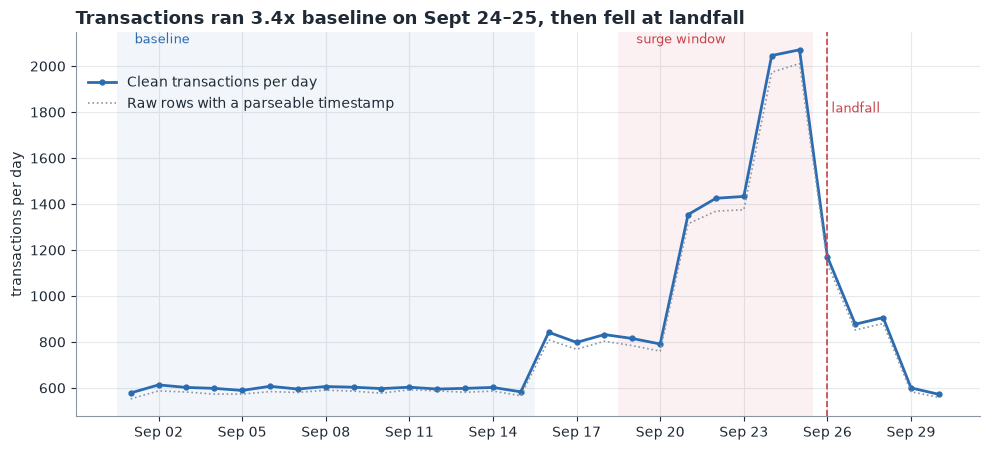

baseline 598/day | surge window 1,419/day | peak 2,058/day | landfall day 1,170


In [15]:
daily_raw_rows = (pd.to_datetime(raw['transactions']['timestamp'].str.strip(), format='mixed', errors='coerce')
                  .dt.normalize().value_counts().reindex(SEPT).fillna(0))
daily_units = tx.groupby('date')['quantity'].sum().reindex(SEPT)
daily_txn = tx.groupby('date').size().reindex(SEPT)

fig, ax = plt.subplots()
ax.plot(SEPT, daily_txn, marker='o', ms=3.5, color=BLUE, lw=2, label='Clean transactions per day')
ax.plot(SEPT, daily_raw_rows, color=MUTED, lw=1.2, ls=':', label='Raw rows with a parseable timestamp')
mark_windows(ax)
date_axis(ax)
base_txn = daily_txn[BASELINE[0]:BASELINE[1]].mean()
peak_txn = daily_txn[PEAK[0]:PEAK[1]].mean()
ax.set_title(f'Transactions ran {peak_txn / base_txn:.1f}x baseline on Sept 24–25, then fell at landfall')
ax.set_ylabel('transactions per day')
ax.legend(loc='upper left', bbox_to_anchor=(0, 0.92))
plt.tight_layout(); save(fig, '01_daily_transactions'); plt.show()

print(f'baseline {base_txn:,.0f}/day | surge window {daily_txn[SURGE[0]:SURGE[1]].mean():,.0f}/day | '
      f'peak {peak_txn:,.0f}/day | landfall day {daily_txn[LANDFALL_DAY]:,.0f}')

---
Weather: Open-Meteo Historical Weather API

Source: `https://archive-api.open-meteo.com/v1/archive` (free, no key; [docs](https://open-meteo.com/en/docs/historical-weather-api)).

One call requests hourly wind speed, gusts, precipitation and sea-level pressure for all 12 stores, Sept 1 to Oct 1 in UTC. Oct 1 is included because the last evening hours of Sept 30 in Florida fall on Oct 1 in UTC.

We convert from UTC ourselves rather than using the API's `timezone` option, which labels September 2024 hours as UTC−5 when Florida was on UTC−4 (checked in 5.1).

The call retries on server errors. Each successful response is saved to `data/weather_cache/`, and if the API is unreachable the saved copy is used and labeled as such in the `source` column.

In [16]:
OPEN_METEO_URL = 'https://archive-api.open-meteo.com/v1/archive'
HOURLY_VARS = ['wind_speed_10m', 'wind_gusts_10m', 'precipitation', 'pressure_msl']
CACHE_DIR = DATA / 'weather_cache'
RETRY_STATUSES = {429, 500, 502, 503, 504}


def call_open_meteo(params, tries=4, timeout=30):
    # GET with retries on throttling/server errors; any other HTTP error fails immediately
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(OPEN_METEO_URL, params=params, timeout=timeout)
        except (requests.Timeout, requests.ConnectionError) as err:
            if attempt == tries:
                raise
            print(f'  attempt {attempt}: {type(err).__name__}, retrying in {2 ** attempt}s')
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES and attempt < tries:
            print(f'  attempt {attempt}: HTTP {r.status_code}, retrying in {2 ** attempt}s')
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        return r.json(), r.url
    raise RuntimeError('unreachable')


def get_weather(params, cache_name, store_ids):
    # Live call first; on failure, fall back to the last saved live response (and say so)
    cache = CACHE_DIR / cache_name
    try:
        payload, url = call_open_meteo(params)
        fetched = datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')
        CACHE_DIR.mkdir(exist_ok=True)
        cache.write_text(json.dumps({'fetched_at_utc': fetched, 'request_url': url, 'store_ids': store_ids,
                                     'response': payload}), encoding='utf-8')
        source = f'open-meteo live ({fetched})'
    except requests.RequestException as err:
        if not cache.exists():
            raise RuntimeError(f'Open-Meteo unreachable and no saved response at {cache}') from err
        print(f'Live call failed ({type(err).__name__}); using the saved response from the last successful call.')
        saved = json.loads(cache.read_text(encoding='utf-8'))
        assert saved['store_ids'] == store_ids, 'saved response is for different locations'
        payload, url = saved['response'], saved['request_url']
        source = f'open-meteo saved response ({saved["fetched_at_utc"]})'
    return payload, url, source


store_ids = stores['store_id'].tolist()
params = {
    'latitude': ','.join(f'{x:.4f}' for x in stores['latitude']),
    'longitude': ','.join(f'{x:.4f}' for x in stores['longitude']),
    'start_date': '2024-09-01', 'end_date': '2024-10-01',
    'hourly': ','.join(HOURLY_VARS),
    'timezone': 'GMT',                      # ask for UTC and convert ourselves (see 5.1)
    'wind_speed_unit': 'mph', 'precipitation_unit': 'inch',
}
payload, request_url, WEATHER_SOURCE = get_weather(params, 'open_meteo_hourly_utc_sept2024.json', store_ids)
print('source :', WEATHER_SOURCE)
print('request:', request_url[:160] + '...')
print('locations returned:', len(payload), '| utc_offset_seconds:', {loc['utc_offset_seconds'] for loc in payload},
      '| units:', payload[0]['hourly_units'])

source : open-meteo live (2026-11-14 04:16 UTC)
request: https://archive-api.open-meteo.com/v1/archive?latitude=30.4383%2C29.6516%2C30.3322%2C27.9506%2C27.7676%2C29.2108%2C28.0395%2C28.5383%2C28.2920%2C30.4213%2C26.64...
locations returned: 12 | utc_offset_seconds: {0} | units: {'time': 'iso8601', 'wind_speed_10m': 'mp/h', 'wind_gusts_10m': 'mp/h', 'precipitation': 'inch', 'pressure_msl': 'hPa'}


In [17]:
def parse_hourly(payload, store_ids):
    # One row per store per UTC hour; the API returns locations in request order
    assert len(payload) == len(store_ids)
    frames = []
    for sid, loc in zip(store_ids, payload):
        assert loc['utc_offset_seconds'] == 0, 'expected UTC timestamps'
        h = pd.DataFrame(loc['hourly'])
        h.insert(0, 'store_id', sid)
        h['grid_lat'], h['grid_lon'] = loc['latitude'], loc['longitude']
        frames.append(h)
    w = pd.concat(frames, ignore_index=True)
    w['time_utc'] = pd.to_datetime(w.pop('time')).dt.tz_localize('UTC')     # API strings -> tz-aware UTC
    w['time_local'] = w['time_utc'].dt.tz_convert(TZ)                         # DST-aware: EDT = UTC-4 in Sept
    w['date'] = w['time_local'].dt.tz_localize(None).dt.normalize()           # local calendar day, same as sales
    w['date_utc'] = w['time_utc'].dt.tz_localize(None).dt.normalize()
    return w


hourly = parse_hourly(payload, store_ids)
hourly['source'] = WEATHER_SOURCE
print(f'{len(hourly):,} hourly rows = {hourly["store_id"].nunique()} stores x {hourly.groupby("store_id").size().iloc[0]} hours')
print('missing values per variable:', hourly[HOURLY_VARS].isna().sum().to_dict())
print('UTC offset in local time column:', hourly['time_local'].dt.strftime('%z').unique().tolist())

# Grid snapping: how far is each weather grid point from its store?
snap = hourly.groupby('store_id')[['grid_lat', 'grid_lon']].first().join(stores.set_index('store_id')[['latitude', 'longitude']])
snap['grid_offset_mi'] = haversine_mi(snap['latitude'], snap['longitude'], snap['grid_lat'], snap['grid_lon']).round(1)
print('grid point distance from store (mi): max', snap['grid_offset_mi'].max())


def daily_weather(h, day_col):
    return (h.groupby(['store_id', day_col])
            .agg(wind_max_mph=('wind_speed_10m', 'max'), gust_max_mph=('wind_gusts_10m', 'max'),
                 precip_in=('precipitation', 'sum'), pressure_min_hpa=('pressure_msl', 'min'),
                 hours=('wind_speed_10m', 'size'))
            .reset_index().rename(columns={day_col: 'date'}))


weather_store_day = daily_weather(hourly, 'date')
weather_store_day = weather_store_day[weather_store_day['date'].between(SEPT[0], SEPT[-1])].reset_index(drop=True)
assert (weather_store_day['hours'] == 24).all(), 'every local day must have 24 hourly readings'
assert len(weather_store_day) == 12 * 30
weather_store_day['source'] = WEATHER_SOURCE

# The same aggregation on UTC days, kept only to show what a misaligned join would do (Q3)
weather_store_day_utc = daily_weather(hourly, 'date_utc')
weather_store_day_utc = weather_store_day_utc[weather_store_day_utc['date'].between(SEPT[0], SEPT[-1])]

WEATHER_VARS = ['wind_max_mph', 'gust_max_mph', 'precip_in', 'pressure_min_hpa']
weather_state = weather_store_day.groupby('date')[WEATHER_VARS].mean().reindex(SEPT)        # average store's day
weather_state_utc = weather_store_day_utc.groupby('date')[WEATHER_VARS].mean().reindex(SEPT)
weather_state.loc['2024-09-23':'2024-09-28'].round(2)

8,928 hourly rows = 12 stores x 744 hours
missing values per variable: {'wind_speed_10m': 0, 'wind_gusts_10m': 0, 'precipitation': 0, 'pressure_msl': 0}
UTC offset in local time column: ['-0400']
grid point distance from store (mi): max 4.2


,wind_max_mph,gust_max_mph,precip_in,pressure_min_hpa
2024-09-23,9.47,18.30,0.01,1011.49
2024-09-24,10.64,20.95,0.03,1011.48
2024-09-25,13.87,28.38,0.30,1009.18
2024-09-26,31.45,58.35,0.88,995.75
2024-09-27,27.93,54.83,0.31,997.36
2024-09-28,11.26,23.22,0.33,1010.52


### 5.1 Checking the time-zone handling

NHC's landfall time, 03:10 UTC on Sept 27, should convert to 11:10 PM EDT on Sept 26. A second small API call for Tallahassee, using the API's own conversion, is compared with ours hour by hour.

In [18]:
print('NHC landfall 2024-09-27 03:10 UTC ->', pd.Timestamp('2024-09-27 03:10', tz='UTC').tz_convert(TZ))

check_params = {'latitude': f'{stores.loc[0, "latitude"]:.4f}', 'longitude': f'{stores.loc[0, "longitude"]:.4f}',
                'start_date': '2024-09-26', 'end_date': '2024-09-27', 'hourly': 'pressure_msl',
                'timezone': 'America/New_York'}
check_payload, _, check_source = get_weather(check_params, 'open_meteo_tz_check_tallahassee.json', [stores.loc[0, 'store_id']])
check_payload = check_payload[0] if isinstance(check_payload, list) else check_payload
api_offset = pd.Timedelta(seconds=check_payload['utc_offset_seconds'])

# Undo the API's own offset to get back to UTC, then line its rows up with ours
api = pd.DataFrame({'api_local_label': pd.to_datetime(check_payload['hourly']['time']),
                    'api_pressure': check_payload['hourly']['pressure_msl']})
api['time_utc'] = (api['api_local_label'] - api_offset).dt.tz_localize('UTC')
ours = hourly.loc[hourly['store_id'] == stores.loc[0, 'store_id'], ['time_utc', 'time_local', 'pressure_msl']]
cmp_tz = api.merge(ours, on='time_utc', how='inner', validate='one_to_one')
assert (cmp_tz['api_pressure'] == cmp_tz['pressure_msl']).all(), 'the two calls disagree on the data itself'
cmp_tz['our_local_label'] = cmp_tz['time_local'].dt.tz_localize(None)
cmp_tz['hours_apart'] = (cmp_tz['our_local_label'] - cmp_tz['api_local_label']) / pd.Timedelta(hours=1)

print(f"API offset for timezone=America/New_York: {check_payload['utc_offset_seconds']} s "
      f"({check_payload['timezone_abbreviation']}); true offset in Sept 2024: -14400 s (EDT). Source: {check_source}")
print('hours between the API label and the DST-aware label:', sorted(cmp_tz['hours_apart'].unique()))
display(cmp_tz.loc[cmp_tz['time_utc'].between('2024-09-27 00:00', '2024-09-27 06:00'),
                   ['time_utc', 'our_local_label', 'api_local_label', 'hours_apart', 'pressure_msl']].reset_index(drop=True))

lowest = ours.loc[ours['pressure_msl'].idxmin()]
api_label = (lowest['time_utc'].tz_localize(None) + api_offset)
print(f"Tallahassee's lowest pressure, {lowest['pressure_msl']} hPa, was at {lowest['time_utc']:%Y-%m-%d %H:%M} UTC = "
      f"{lowest['time_local']:%Y-%m-%d %H:%M} EDT (day {lowest['time_local']:%b %d}). "
      f"The API's conversion labels it {api_label:%Y-%m-%d %H:%M} (day {api_label:%b %d}).")

NHC landfall 2024-09-27 03:10 UTC -> 2024-09-26 23:10:00-04:00
API offset for timezone=America/New_York: -18000 s (GMT-5); true offset in Sept 2024: -14400 s (EDT). Source: open-meteo live (2026-11-14 04:16 UTC)
hours between the API label and the DST-aware label: [np.float64(1.0)]


,time_utc,our_local_label,api_local_label,hours_apart,pressure_msl
0,2024-09-27 00:00:00+00:00,2024-09-26 20:00:00,2024-09-26 19:00:00,1.0,993.2
1,2024-09-27 01:00:00+00:00,2024-09-26 21:00:00,2024-09-26 20:00:00,1.0,990.3
2,2024-09-27 02:00:00+00:00,2024-09-26 22:00:00,2024-09-26 21:00:00,1.0,986.0
3,2024-09-27 03:00:00+00:00,2024-09-26 23:00:00,2024-09-26 22:00:00,1.0,982.0
4,2024-09-27 04:00:00+00:00,2024-09-27 00:00:00,2024-09-26 23:00:00,1.0,977.3
5,2024-09-27 05:00:00+00:00,2024-09-27 01:00:00,2024-09-27 00:00:00,1.0,978.8
6,2024-09-27 06:00:00+00:00,2024-09-27 02:00:00,2024-09-27 01:00:00,1.0,984.7


Tallahassee's lowest pressure, 977.3 hPa, was at 2024-09-27 04:00 UTC = 2024-09-27 00:00 EDT (day Sep 27). The API's conversion labels it 2024-09-26 23:00 (day Sep 26).


5.2 Joining weather to sales, with checks

Both tables are keyed on the local calendar day. The joins are left joins from sales with `validate='one_to_one'`, and the row counts and unit totals are checked afterwards.

In [19]:
def checked_join(left, right, on, label):
    merged = left.merge(right, on=on, how='left', validate='one_to_one', indicator=True)
    assert len(merged) == len(left), f'{label}: row count changed'
    assert merged['_merge'].eq('both').all(), f'{label}: {merged["_merge"].ne("both").sum()} rows without weather'
    assert merged['units'].sum() == left['units'].sum(), f'{label}: units total changed'
    print(f'{label:>10}: {len(left)} rows in -> {len(merged)} rows out, all matched; units unchanged ({left["units"].sum():,})')
    return merged.drop(columns='_merge')


state_sales = tx.groupby('date')['quantity'].sum().reindex(SEPT).rename('units').rename_axis('date').reset_index()
state_wx = checked_join(state_sales, weather_state.rename_axis('date').reset_index(), 'date', 'statewide')

store_sales = tx.groupby(['store_id', 'date'])['quantity'].sum().rename('units').reset_index()
store_wx = checked_join(store_sales, weather_store_day.drop(columns='hours'), ['store_id', 'date'], 'store-day')
state_wx.loc[state_wx['date'].between('2024-09-22', '2024-09-28'), ['date', 'units'] + WEATHER_VARS].set_index('date').round(2)

 statewide: 30 rows in -> 30 rows out, all matched; units unchanged (49,775)
 store-day: 360 rows in -> 360 rows out, all matched; units unchanged (49,775)


,units,wind_max_mph,gust_max_mph,precip_in,pressure_min_hpa
date,,,,,
2024-09-22,2869,8.96,17.85,0.03,1011.18
2024-09-23,2829,9.47,18.30,0.01,1011.49
2024-09-24,4074,10.64,20.95,0.03,1011.48
2024-09-25,4114,13.87,28.38,0.30,1009.18
2024-09-26,2300,31.45,58.35,0.88,995.75
2024-09-27,1727,27.93,54.83,0.31,997.36
2024-09-28,1793,11.26,23.22,0.33,1010.52


---
Load: write the clean tables to a SQLite warehouse

The clean tables, the SKU map, the weather tables and the decision log are written to `output/walmart_clean.db`, then read back once to confirm.

In [20]:
def to_sql_ready(df):
    out = df.copy()
    for c in out.columns:
        if isinstance(out[c].dtype, pd.DatetimeTZDtype):
            out[c] = out[c].dt.strftime('%Y-%m-%d %H:%M:%S%z')
        elif pd.api.types.is_datetime64_any_dtype(out[c]):
            out[c] = out[c].dt.strftime('%Y-%m-%d')
    return out


warehouse = OUT / 'walmart_clean.db'
tables = {
    'fact_transactions': tx, 'dim_store': stores, 'dim_product': product_dim, 'map_sku': sku_map,
    'dim_distribution_center': dcs, 'fact_daily_sales_summary': dss, 'fact_inventory_levels': inv,
    'fact_weather_hourly': hourly.drop(columns=['date_utc']), 'fact_weather_store_day': weather_store_day,
    'decision_log': pd.DataFrame(decision_log),
}
with sqlite3.connect(warehouse) as wh:
    for name, df in tables.items():
        to_sql_ready(df).to_sql(name, wh, if_exists='replace', index=False)
    check = pd.read_sql('''
        SELECT p.product, SUM(t.quantity) AS units
        FROM fact_transactions t JOIN dim_product p USING (product_id)
        WHERE t.date BETWEEN '2024-09-19' AND '2024-09-25'
        GROUP BY p.product ORDER BY units DESC LIMIT 3''', wh)
print('wrote', warehouse.name, '->', {k: len(v) for k, v in tables.items()})
check

wrote walmart_clean.db -> {'fact_transactions': 25501, 'dim_store': 12, 'dim_product': 20, 'map_sku': 45, 'dim_distribution_center': 5, 'fact_daily_sales_summary': 3600, 'fact_inventory_levels': 4320, 'fact_weather_hourly': 8928, 'fact_weather_store_day': 360, 'decision_log': 20}


,product,units
0,Pop-Tarts Strawberry,2753
1,Bottled Water 24-Pack,2340
2,AA Batteries 4-Pack,1764


## FINALLY THE QUESTIONS!!!

---
## Q1. Which categories surged most in the 7 days before landfall?

For each category, average daily units in the surge window (Sept 19–25) are compared with the baseline (Sept 1–15). The `t` column is a Welch t-statistic on daily totals. Sept 24–25 alone is shown as a check.

In [21]:
cat_daily = (tx.pivot_table(index='date', columns='category', values='quantity', aggfunc='sum')
             .reindex(SEPT).fillna(0))
cat_daily['ALL CATEGORIES'] = cat_daily.sum(axis=1)


def surge_table(daily, base=BASELINE, surge=SURGE, peak=PEAK):
    b, s, p = daily.loc[base[0]:base[1]], daily.loc[surge[0]:surge[1]], daily.loc[peak[0]:peak[1]]
    out = pd.DataFrame({'baseline_per_day': b.mean(), 'surge_per_day': s.mean(), 'peak_per_day': p.mean()})
    out['surge_pct_increase'] = 100 * (out['surge_per_day'] / out['baseline_per_day'] - 1)
    out['peak_pct_increase'] = 100 * (out['peak_per_day'] / out['baseline_per_day'] - 1)
    out['t'] = (s.mean() - b.mean()) / np.sqrt(b.var() / len(b) + s.var() / len(s))   # Welch t on daily totals
    return out


q1 = surge_table(cat_daily).sort_values('surge_pct_increase', ascending=False)
q1['rank_surge'] = q1['surge_pct_increase'].drop('ALL CATEGORIES').rank(ascending=False)
q1['rank_peak'] = q1['peak_pct_increase'].drop('ALL CATEGORIES').rank(ascending=False)
TOP5 = q1.drop('ALL CATEGORIES').index[:5].tolist()
q1.round(1)

,baseline_per_day,surge_per_day,peak_per_day,surge_pct_increase,peak_pct_increase,t,rank_surge,rank_peak
category,,,,,,,,
Breakfast,75.1,393.3,653.0,423.9,769.9,4.1,1.0,1.0
Emergency,365.8,1047.3,1538.5,186.3,320.6,4.4,2.0,2.0
ALL CATEGORIES,1142.5,2825.9,4094.0,147.3,258.3,4.3,NaN,NaN
Electronics,73.7,181.6,264.0,146.5,258.4,4.1,3.0,3.0
Entertainment,105.4,240.9,353.0,128.5,234.9,4.1,4.0,5.0
Alcohol,63.5,144.3,198.0,127.1,211.6,3.9,5.0,6.0
Health,43.6,98.3,151.0,125.4,246.3,3.6,6.0,4.0
Household,89.1,186.6,264.0,109.5,196.4,4.1,7.0,7.0
Grocery,176.8,318.4,412.0,80.1,133.0,4.5,8.0,8.0


In [22]:
# Sensitivity: does the top 5 change if the windows change?
alt_windows = {
    'ours: base Sep 1-15, surge Sep 19-25': (BASELINE, SURGE),
    'base runs into the rise (Sep 1-18)':   ((BASELINE[0], pd.Timestamp('2024-09-18')), SURGE),
    'surge = 3 days before landfall':       (BASELINE, (pd.Timestamp('2024-09-23'), pd.Timestamp('2024-09-25'))),
    'surge includes landfall (Sep 20-26)':  (BASELINE, (pd.Timestamp('2024-09-20'), LANDFALL_DAY)),
}
sens = {}
for name, (b, s) in alt_windows.items():
    t = surge_table(cat_daily.drop(columns='ALL CATEGORIES'), base=b, surge=s)
    sens[name] = t['surge_pct_increase'].round(0).astype(int).astype(str) + '%  (#' + \
                 t['surge_pct_increase'].rank(ascending=False).astype(int).astype(str) + ')'
display(pd.DataFrame(sens).loc[q1.drop('ALL CATEGORIES').index])

,"ours: base Sep 1-15, surge Sep 19-25",base runs into the rise (Sep 1-18),surge = 3 days before landfall,surge includes landfall (Sep 20-26)
category,,,,
Breakfast,424% (#1),336% (#1),637% (#1),451% (#1)
Emergency,186% (#2),165% (#2),281% (#2),200% (#2)
Electronics,146% (#3),135% (#3),214% (#3),156% (#3)
Entertainment,129% (#4),117% (#4),201% (#5),138% (#4)
Alcohol,127% (#5),116% (#5),176% (#6),136% (#5)
Health,125% (#6),110% (#6),207% (#4),133% (#6)
Household,109% (#7),98% (#7),160% (#7),112% (#7)
Grocery,80% (#8),72% (#8),118% (#8),81% (#8)
Baby,56% (#9),52% (#9),80% (#9),58% (#9)


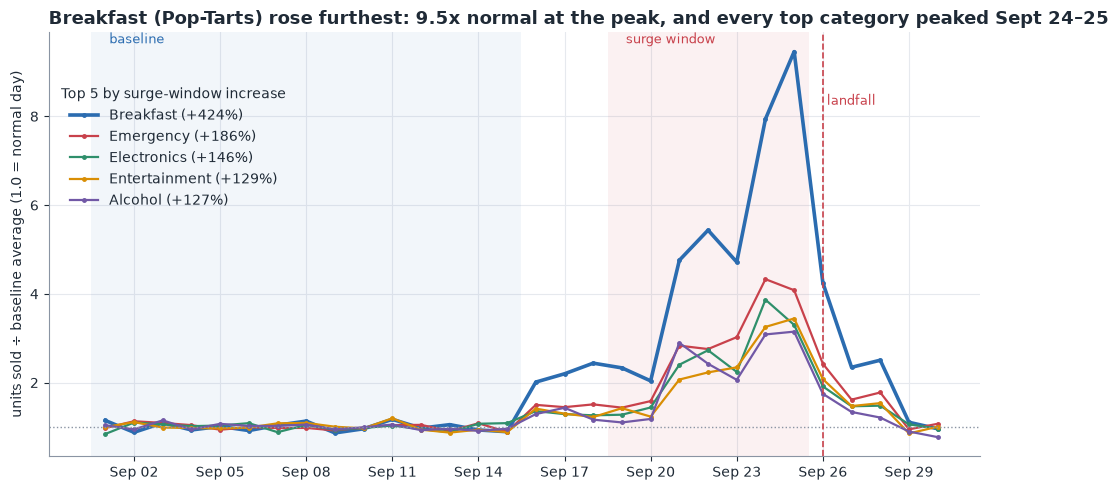

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
indexed = cat_daily[TOP5] / cat_daily.loc[BASELINE[0]:BASELINE[1], TOP5].mean()
for color, cat in zip(PALETTE, TOP5):
    lw = 2.6 if cat == TOP5[0] else 1.6
    ax.plot(SEPT, indexed[cat], color=color, lw=lw, marker='o', ms=2.5,
            label=f'{cat} (+{q1.loc[cat, "surge_pct_increase"]:.0f}%)')
ax.axhline(1, color=MUTED, lw=1, ls=':')
mark_windows(ax)
date_axis(ax)
ax.set_ylabel('units sold ÷ baseline average (1.0 = normal day)')
ax.set_title(f'Breakfast (Pop-Tarts) rose furthest: {indexed[TOP5[0]].max():.1f}x normal at the peak, '
             'and every top category peaked Sept 24–25')
ax.legend(title='Top 5 by surge-window increase', loc='upper left', bbox_to_anchor=(0, 0.9))
plt.tight_layout(); save(fig, '02_q1_top5_daily_index'); plt.show()

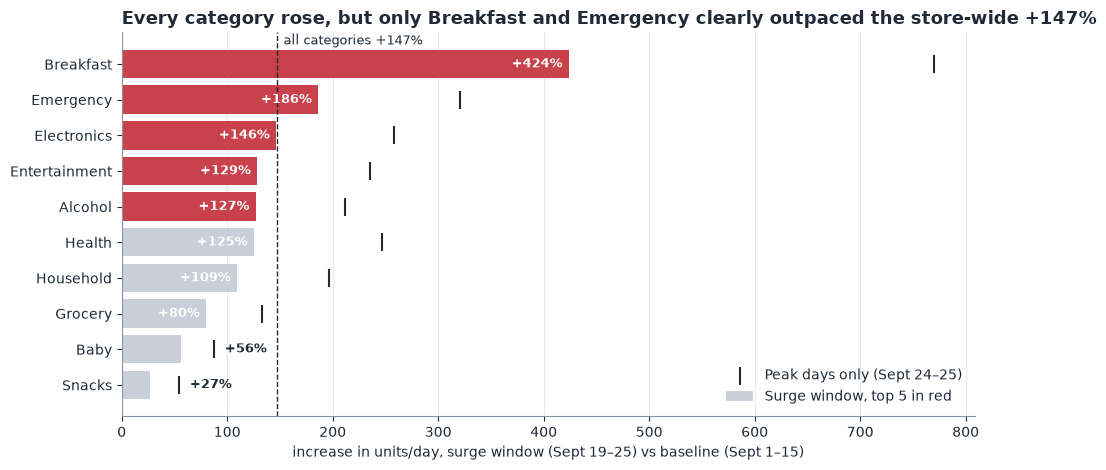

In [24]:
plot = q1.drop('ALL CATEGORIES').sort_values('surge_pct_increase')
fig, ax = plt.subplots(figsize=(10, 4.8))
colors = [RED if c in TOP5 else '#c9cfd8' for c in plot.index]
ax.barh(plot.index, plot['surge_pct_increase'], color=colors, label='Surge window, top 5 in red')
ax.scatter(plot['peak_pct_increase'], plot.index, color=INK, marker='|', s=160, zorder=3,
           label='Peak days only (Sept 24–25)')
for y, (v, pk) in enumerate(zip(plot['surge_pct_increase'], plot['peak_pct_increase'])):
    inside = v > 60
    ax.text(v - 6 if inside else pk + 10, y, f'+{v:.0f}%', va='center', ha='right' if inside else 'left',
            fontsize=9, color='white' if inside else INK, fontweight='bold')
all_pct = q1.loc['ALL CATEGORIES', 'surge_pct_increase']
ax.axvline(all_pct, color=INK, ls='--', lw=1)
ax.text(all_pct + 6, len(plot) - 0.45, f'all categories +{all_pct:.0f}%', fontsize=9)
ax.set_xlabel('increase in units/day, surge window (Sept 19–25) vs baseline (Sept 1–15)')
ax.set_title(f'Every category rose, but only Breakfast and Emergency clearly outpaced the store-wide +{all_pct:.0f}%')
ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)
plt.tight_layout(); save(fig, '03_q1_category_increase'); plt.show()

In [25]:
# Which products drive the top categories?
prod_daily = (tx.pivot_table(index='date', columns='product', values='quantity', aggfunc='sum')
              .reindex(SEPT).fillna(0))
prod_surge = surge_table(prod_daily).join(product_dim.set_index('product')['category'])
prod_surge = prod_surge.sort_values('surge_pct_increase', ascending=False)
prod_surge[['category', 'baseline_per_day', 'surge_per_day', 'surge_pct_increase', 'peak_pct_increase', 't']].round(1)

,category,baseline_per_day,surge_per_day,surge_pct_increase,peak_pct_increase,t
product,,,,,,
Pop-Tarts Strawberry,Breakfast,75.1,393.3,423.9,769.9,4.1
Bottled Water 24-Pack,Emergency,111.3,334.3,200.3,329.3,4.6
Heavy Duty Tarp,Emergency,44.9,134.3,198.9,351.8,4.0
LED Flashlight,Emergency,59.3,176.0,196.6,344.1,3.8
AA Batteries 4-Pack,Emergency,91.6,252.0,175.1,306.1,4.5
Monopoly Board Game,Entertainment,44.5,118.9,167.3,319.4,3.7
Portable Phone Charger,Electronics,44.8,115.7,158.3,271.7,4.2
Emergency Candles,Emergency,58.6,150.7,157.2,278.8,4.1
Streaming Stick,Electronics,28.9,65.9,128.1,237.8,3.9


**Answer (Q1).** Units across all categories rose 147%. The largest increases:

| Category | Baseline/day | Surge/day | Increase |
|---|---|---|---|
| Breakfast | 75 | 393 | +424% |
| Emergency | 366 | 1,047 | +186% |
| Electronics | 74 | 182 | +146% |
| Entertainment | 105 | 241 | +129% |
| Alcohol | 64 | 144 | +127% |

Only Breakfast and Emergency rose clearly faster than the store as a whole. The ranking holds under the alternative windows. All five categories stepped up on Sept 16 and Sept 21, peaked Sept 24–25 and were back to normal by Sept 29. Breakfast is almost entirely Pop-Tarts; Emergency is water, tarps, flashlights, batteries and candles. Snacks rose only 27%.

---
## Q2. The Pop-Tarts effect: fragmented SKUs vs. one consolidated product

The raw file grouped by SKU (no cleaning) is compared with the cleaned, consolidated product, including where Pop-Tarts ranks among all items.

In [26]:
PT = 'POPTARTS-STRAWBERRY'
PT_SKUS = SKU_GROUPS[PT][1]

# Uncleaned view: raw file, naive parsing, no dedup, no sign fix, no SKU consolidation
naive = raw['transactions'].copy()
naive['date'] = pd.to_datetime(naive['timestamp'], format='mixed', errors='coerce').dt.normalize()
naive['quantity'] = naive['quantity'].astype(int)
naive = naive.dropna(subset=['date'])
naive_pt = naive[naive['sku'].isin(PT_SKUS)]
raw_by_sku = naive_pt.pivot_table(index='date', columns='sku', values='quantity', aggfunc='sum').reindex(SEPT).fillna(0)
raw_by_name = naive_pt.pivot_table(index='date', columns='product_name', values='quantity', aggfunc='sum').reindex(SEPT).fillna(0)

# Clean view: all four SKUs are one product
clean_pt = tx[tx['product_id'] == PT].groupby('date')['quantity'].sum().reindex(SEPT).fillna(0)


def window_stats(series):
    b = series.loc[BASELINE[0]:BASELINE[1]].mean()
    return pd.Series({'baseline/day': b, 'surge/day': series.loc[SURGE[0]:SURGE[1]].mean(),
                      'peak day (Sept 25)': series.loc['2024-09-25'], 'surge multiple': series.loc[SURGE[0]:SURGE[1]].mean() / b,
                      'peak multiple': series.loc['2024-09-25'] / b})


views = pd.DataFrame({f'raw SKU {c}': window_stats(raw_by_sku[c]) for c in raw_by_sku.columns})
views['largest raw name variant'] = window_stats(raw_by_name[raw_by_name.sum().idxmax()])
views['CLEAN: consolidated'] = window_stats(clean_pt)
display(views.T.round(1))
print(f'{len(PT_SKUS)} SKUs and {naive_pt["product_name"].nunique()} name spellings in the raw data for one product.')
print(f'Clean total for September: {clean_pt.sum():,.0f} units '
      f'(raw sum across all four SKUs: {raw_by_sku.values.sum():,.0f}; the gap is missing timestamps, duplicates and sign errors)')

,baseline/day,surge/day,peak day (Sept 25),surge multiple,peak multiple
raw SKU POPTART-STRAW,17.9,90.6,134.0,5.1,7.5
raw SKU PT-12,20.4,103.3,240.0,5.1,11.8
raw SKU PT_STRAWBERRY,18.0,91.9,161.0,5.1,8.9
raw SKU SKU#459812,16.7,90.1,139.0,5.4,8.3
largest raw name variant,13.7,66.4,97.0,4.8,7.1
CLEAN: consolidated,75.1,393.3,710.0,5.2,9.5


4 SKUs and 6 name spellings in the raw data for one product.
Clean total for September: 5,216 units (raw sum across all four SKUs: 4,986; the gap is missing timestamps, duplicates and sign errors)


In [27]:
# How Pop-Tarts ranks among all items in the surge window, raw vs clean
naive_surge = naive[naive['date'].between(*SURGE)]
raw_rank = (naive_surge.groupby('sku')['quantity'].sum() / 7).sort_values(ascending=False).to_frame('units_per_day')
raw_rank['rank'] = np.arange(1, len(raw_rank) + 1)
clean_rank = (tx[tx['date'].between(*SURGE)].groupby('product')['quantity'].sum() / 7).sort_values(ascending=False).to_frame('units_per_day')
clean_rank['rank'] = np.arange(1, len(clean_rank) + 1)

best_raw_sku = raw_rank.loc[PT_SKUS].sort_values('rank').iloc[0]
print('Raw view, Pop-Tart SKU ranks among 45 SKUs  :', raw_rank.loc[PT_SKUS, 'rank'].sort_values().to_dict())
print('Clean view, Pop-Tarts rank among 20 products:', int(clean_rank.loc['Pop-Tarts Strawberry', 'rank']))
display(clean_rank.head(6).round(1))

Raw view, Pop-Tart SKU ranks among 45 SKUs  : {'PT-12': 3, 'PT_STRAWBERRY': 5, 'POPTART-STRAW': 6, 'SKU#459812': 7}
Clean view, Pop-Tarts rank among 20 products: 1


,units_per_day,rank
product,,
Pop-Tarts Strawberry,393.3,1
Bottled Water 24-Pack,334.3,2
AA Batteries 4-Pack,252.0,3
LED Flashlight,176.0,4
Emergency Candles,150.7,5
Light Beer 24-Pack,144.3,6


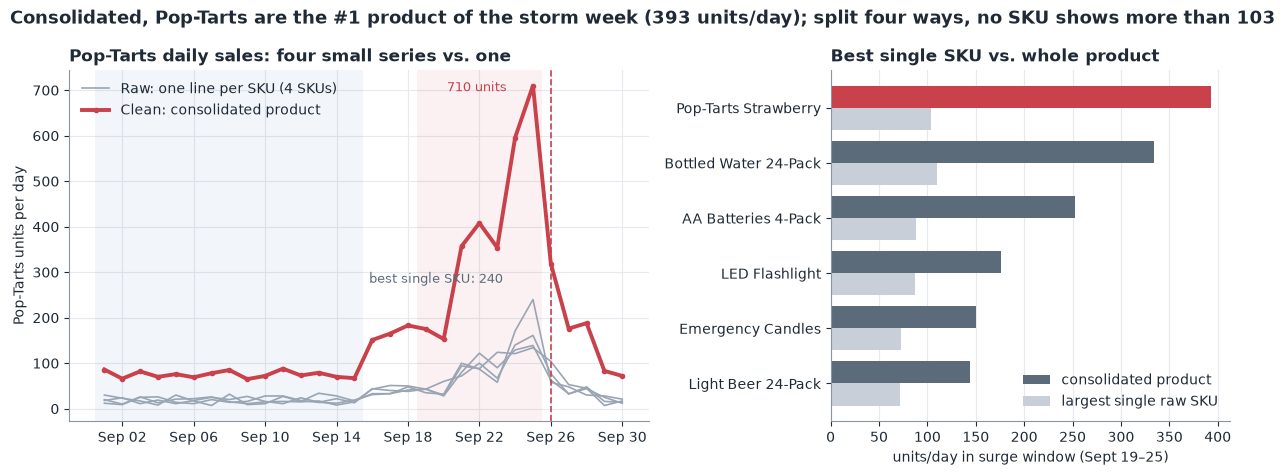

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={'width_ratios': [1.45, 1]})

ax = axes[0]
for i, sku in enumerate(raw_by_sku.columns):
    ax.plot(SEPT, raw_by_sku[sku], color='#9aa5b4', lw=1.2, label='Raw: one line per SKU (4 SKUs)' if i == 0 else None)
ax.plot(SEPT, clean_pt, color=RED, lw=2.8, marker='o', ms=3, label='Clean: consolidated product')
mark_windows(ax, label=False)
date_axis(ax, every=4)
ax.set_ylabel('Pop-Tarts units per day')
ax.set_title('Pop-Tarts daily sales: four small series vs. one', fontsize=12)
ax.legend(loc='upper left')
ax.annotate(f'{clean_pt.max():.0f} units', (clean_pt.idxmax(), clean_pt.max()), textcoords='offset points',
            xytext=(-62, -4), fontsize=9, color=RED)
ax.annotate(f'best single SKU: {raw_by_sku.max().max():.0f}', (raw_by_sku.max(axis=1).idxmax(), raw_by_sku.max().max()),
            textcoords='offset points', xytext=(-118, 12), fontsize=9, color=SLATE)

# Largest single raw SKU vs consolidated product, surge window, for the top products
ax = axes[1]
top_products = clean_rank.head(6).index[::-1]
pid_of = product_dim.set_index('product')['product_id']
best_single = [raw_rank.loc[SKU_GROUPS[pid_of[p]][1], 'units_per_day'].max() for p in top_products]
y = np.arange(len(top_products))
ax.barh(y + 0.2, clean_rank.loc[top_products, 'units_per_day'], height=0.4, color=[RED if p.startswith('Pop') else SLATE for p in top_products], label='consolidated product')
ax.barh(y - 0.2, best_single, height=0.4, color='#c9cfd8', label='largest single raw SKU')
ax.set_yticks(y, top_products)
ax.set_xlabel('units/day in surge window (Sept 19–25)')
ax.set_title('Best single SKU vs. whole product', fontsize=12)
ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)

fig.suptitle(f'Consolidated, Pop-Tarts are the #1 product of the storm week ({clean_rank.loc["Pop-Tarts Strawberry", "units_per_day"]:.0f} units/day); '
             f'split four ways, no SKU shows more than {raw_rank.loc[PT_SKUS, "units_per_day"].max():.0f}',
             x=0.01, ha='left', fontsize=13, fontweight='bold')
plt.tight_layout(); save(fig, '04_q2_poptarts_fragmented_vs_clean'); plt.show()

**Answer (Q2).** Consolidated, Pop-Tarts sold 75 units/day at baseline, 393/day in the surge week (5.2×) and 710 on Sept 25, the most of any product. In the raw data, the best single Pop-Tart SKU shows 103/day and ranks third, behind two water SKUs.

The surge percentage is about the same in every SKU, so fragmentation hides the volume rather than the trend. That changes the decisions: an order sized from one SKU would cover about a quarter of demand, water would get truck priority over Pop-Tarts, and per-SKU reorder points would miss a product that is selling out.

---
## Q3. How do wind, rain and pressure relate to sales, and is there a lag?

Daily units are correlated with the average store's weather on the same day and on days before and after (lags −3 to +5). The same test is repeated per store and with a deliberately misaligned UTC join. With one storm and 30 days, these correlations describe what happened; they don't show cause.

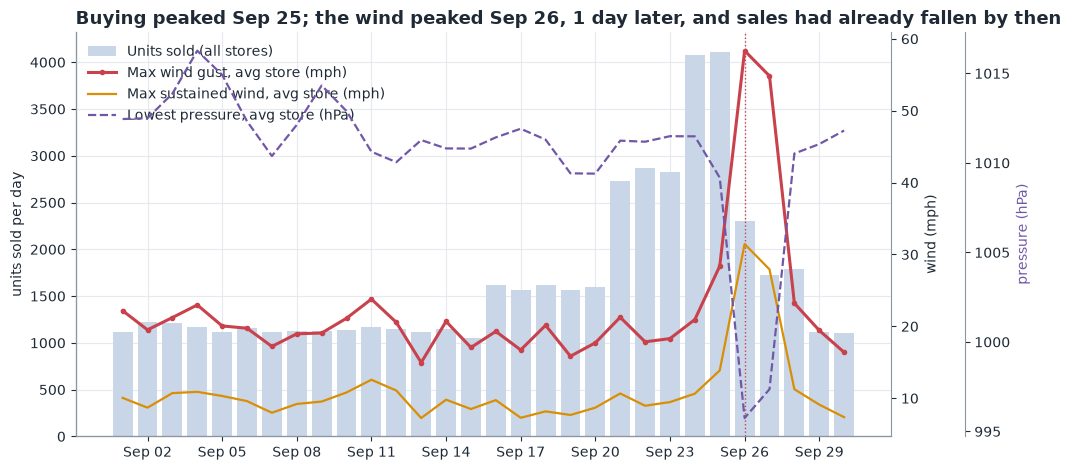

In [29]:
# Overlay: sales vs. the storm's arrival
fig, ax = plt.subplots(figsize=(10.5, 4.8))
ax.bar(SEPT, state_wx['units'], color='#c9d6e8', width=0.8, label='Units sold (all stores)')
ax.set_ylabel('units sold per day')
date_axis(ax)
ax2 = ax.twinx()
ax2.plot(SEPT, weather_state['gust_max_mph'], color=RED, lw=2.2, marker='o', ms=3, label='Max wind gust, avg store (mph)')
ax2.plot(SEPT, weather_state['wind_max_mph'], color=GOLD, lw=1.6, label='Max sustained wind, avg store (mph)')
ax2.set_ylabel('wind (mph)')
ax2.spines['right'].set_visible(True)
ax2.grid(False)
ax3 = ax.twinx()
ax3.spines['right'].set_position(('axes', 1.09)); ax3.spines['right'].set_visible(True)
ax3.plot(SEPT, weather_state['pressure_min_hpa'], color=PURPLE, lw=1.6, ls='--', label='Lowest pressure, avg store (hPa)')
ax3.set_ylabel('pressure (hPa)', color=PURPLE)
ax3.grid(False)
ax.axvline(LANDFALL_DAY, color=RED, ls=':', lw=1)
peak_sales_day = state_wx.loc[state_wx['units'].idxmax(), 'date']
peak_wind_day = weather_state['gust_max_mph'].idxmax()
gap = (peak_wind_day - peak_sales_day).days
ax.set_title(f'Buying peaked {peak_sales_day:%b %d}; the wind peaked {peak_wind_day:%b %d}, '
             f'{gap} day{"s" if gap != 1 else ""} later, and sales had already fallen by then')
handles = sum([a.get_legend_handles_labels()[0] for a in (ax, ax2, ax3)], [])
labels = sum([a.get_legend_handles_labels()[1] for a in (ax, ax2, ax3)], [])
ax.legend(handles, labels, loc='upper left')
plt.tight_layout(); save(fig, '05_q3_sales_vs_weather'); plt.show()

In [30]:
# 1) Same-day correlation and 2) lag scan, statewide (n = 30 minus the lag)
LAGS = range(-3, 6)
lag_rows = []
for k in LAGS:
    for var in WEATHER_VARS:
        future = state_wx[var].shift(-k)                        # weather k days after the sales day
        ok = state_wx['units'].notna() & future.notna()
        lag_rows.append({'lag_days': k, 'variable': var, 'r': state_wx['units'][ok].corr(future[ok]), 'n': int(ok.sum())})
lag_tbl = pd.DataFrame(lag_rows)
lag_wide = lag_tbl.pivot(index='lag_days', columns='variable', values='r')[WEATHER_VARS]
best = lag_tbl.loc[lag_tbl.groupby('variable')['r'].apply(lambda s: s.abs().idxmax())].set_index('variable').loc[WEATHER_VARS]
print('Correlation of daily units with weather k days LATER (statewide):')
display(lag_wide.round(2))
print('Strongest lag per variable:')
display(best.round(2))

Correlation of daily units with weather k days LATER (statewide):


variable,wind_max_mph,gust_max_mph,precip_in,pressure_min_hpa
lag_days,,,,
-3,-0.24,-0.24,-0.64,0.03
-2,-0.11,-0.13,-0.64,-0.06
-1,0.04,0.02,-0.59,-0.13
0,0.22,0.21,-0.32,-0.23
1,0.58,0.58,-0.02,-0.58
2,0.80,0.81,0.02,-0.80
3,0.61,0.63,-0.05,-0.62
4,0.42,0.45,-0.03,-0.43
5,0.34,0.36,-0.10,-0.36


Strongest lag per variable:


,lag_days,r,n
variable,,,
wind_max_mph,2,0.80,28
gust_max_mph,2,0.81,28
precip_in,-3,-0.64,27
pressure_min_hpa,2,-0.80,28


In [31]:
# 4) Robustness: the same lag scan on the store-day panel (each store's own weather)
panel = store_wx.sort_values(['store_id', 'date']).copy()
panel['units_idx'] = panel['units'] / panel.groupby('store_id')['units'].transform(
    lambda s: s[panel.loc[s.index, 'date'].between(*BASELINE)].mean())        # each store vs its own baseline
panel_rows = []
for k in LAGS:
    for var in WEATHER_VARS:
        future = panel.groupby('store_id')[var].shift(-k)
        ok = future.notna()
        panel_rows.append({'lag_days': k, 'variable': var, 'r': panel.loc[ok, 'units_idx'].corr(future[ok]), 'n': int(ok.sum())})
panel_lag = pd.DataFrame(panel_rows).pivot(index='lag_days', columns='variable', values='r')[WEATHER_VARS]

# What the misaligned (UTC-day) join would have reported
utc_rows = []
for k in LAGS:
    future = weather_state_utc['gust_max_mph'].shift(-k).values
    ok = ~np.isnan(future)
    utc_rows.append({'lag_days': k, 'r_utc_days': np.corrcoef(state_wx['units'].values[ok], future[ok])[0, 1]})
tz_effect = pd.DataFrame(utc_rows).set_index('lag_days')
tz_effect.insert(0, 'r_local_days', lag_wide['gust_max_mph'])
tz_effect['difference'] = tz_effect['r_utc_days'] - tz_effect['r_local_days']
print('Store-day panel (n ≈ 360 - 12k): correlation of store units/baseline with that store\'s weather k days later')
display(panel_lag.round(2))
print('Gust correlation: correct local-day join vs. a UTC-day join')
display(tz_effect.round(3))
landfall_gust = pd.DataFrame({'local days (correct)': weather_state.loc['2024-09-25':'2024-09-28', 'gust_max_mph'],
                              'UTC days (misaligned)': weather_state_utc.loc['2024-09-25':'2024-09-28', 'gust_max_mph']})
landfall_gust.round(1)

Store-day panel (n ≈ 360 - 12k): correlation of store units/baseline with that store's weather k days later


variable,wind_max_mph,gust_max_mph,precip_in,pressure_min_hpa
lag_days,,,,
-3,-0.21,-0.21,-0.32,0.03
-2,-0.10,-0.12,-0.32,-0.05
-1,0.03,0.01,-0.30,-0.12
0,0.18,0.18,-0.17,-0.21
1,0.49,0.49,-0.01,-0.52
2,0.69,0.72,0.03,-0.72
3,0.54,0.57,-0.00,-0.56
4,0.37,0.40,-0.02,-0.39
5,0.30,0.33,-0.07,-0.31


Gust correlation: correct local-day join vs. a UTC-day join


,r_local_days,r_utc_days,difference
lag_days,,,
-3,-0.241,-0.245,-0.004
-2,-0.134,-0.162,-0.028
-1,0.018,0.010,-0.008
0,0.214,0.188,-0.026
1,0.576,0.514,-0.062
2,0.809,0.801,-0.008
3,0.635,0.664,0.029
4,0.450,0.447,-0.003
5,0.363,0.364,0.002


,local days (correct),UTC days (misaligned)
2024-09-25,28.4,27.6
2024-09-26,58.4,50.5
2024-09-27,54.8,59.4
2024-09-28,23.2,23.3


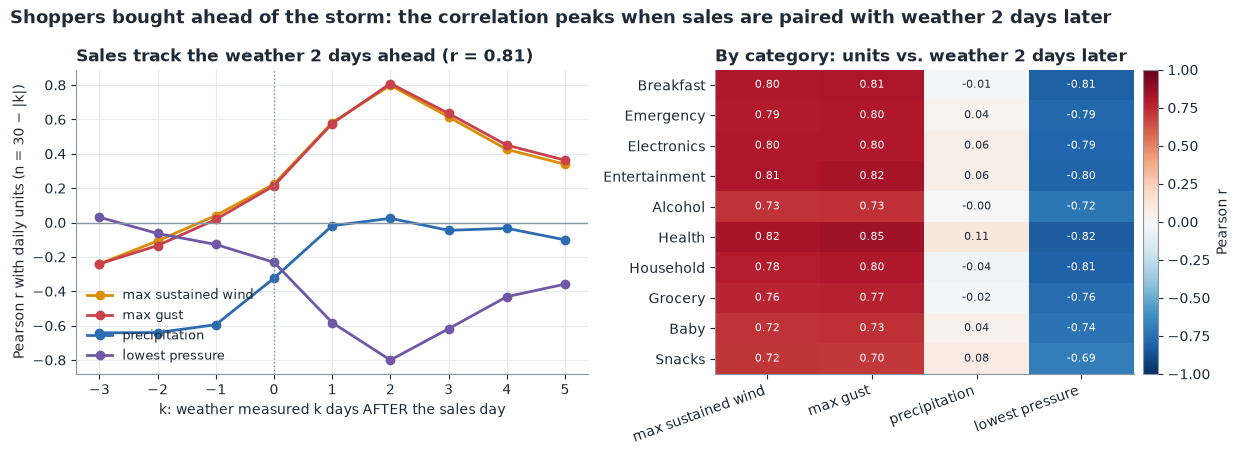

Same-day (k = 0) correlations by category, for comparison:


,max sustained wind,max gust,precipitation,lowest pressure
Breakfast,0.24,0.23,-0.29,-0.25
Emergency,0.24,0.23,-0.32,-0.25
Electronics,0.20,0.18,-0.35,-0.20
Entertainment,0.27,0.26,-0.26,-0.27
Alcohol,0.19,0.18,-0.32,-0.17
Health,0.24,0.24,-0.31,-0.27
Household,0.21,0.20,-0.30,-0.22
Grocery,0.15,0.14,-0.37,-0.15
Baby,0.09,0.08,-0.50,-0.13
Snacks,0.07,0.08,-0.19,-0.01


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={'width_ratios': [1.15, 1]})

ax = axes[0]
names = {'wind_max_mph': 'max sustained wind', 'gust_max_mph': 'max gust', 'precip_in': 'precipitation',
         'pressure_min_hpa': 'lowest pressure'}
for color, var in zip([GOLD, RED, BLUE, PURPLE], WEATHER_VARS):
    ax.plot(lag_wide.index, lag_wide[var], marker='o', color=color, lw=2, label=names[var])
ax.axhline(0, color=MUTED, lw=1)
ax.axvline(0, color=MUTED, lw=1, ls=':')
ax.set_xlabel('k: weather measured k days AFTER the sales day')
ax.set_ylabel('Pearson r with daily units (n = 30 − |k|)')
ax.set_xticks(list(LAGS))
best_gust = best.loc['gust_max_mph']
ax.set_title(f'Sales track the weather {int(best_gust["lag_days"])} days ahead (r = {best_gust["r"]:.2f})', fontsize=12)
ax.legend(loc='lower left', fontsize=9)

ax = axes[1]
heat_lag = int(best_gust['lag_days'])
cats = q1.drop('ALL CATEGORIES').index.tolist()
heat = pd.DataFrame({names[v]: [cat_daily[c].corr(weather_state[v].shift(-heat_lag)) for c in cats] for v in WEATHER_VARS},
                    index=cats)
im = ax.imshow(heat.values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=20, ha='right')
ax.set_yticks(range(len(cats)), cats)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > 0.6 else INK)
ax.grid(False)
ax.set_title(f'By category: units vs. weather {heat_lag} days later', fontsize=12)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label='Pearson r')
fig.suptitle('Shoppers bought ahead of the storm: the correlation peaks when sales are paired with weather 2 days later',
             x=0.01, ha='left', fontsize=13, fontweight='bold')
plt.tight_layout(); save(fig, '06_q3_lag_and_category_heatmap'); plt.show()

same_day = pd.DataFrame({names[v]: [cat_daily[c].corr(weather_state[v]) for c in cats] for v in WEATHER_VARS}, index=cats)
print('Same-day (k = 0) correlations by category, for comparison:')
same_day.round(2)

In [33]:
# 3) Escalation timing: first day each series moves > 3 SD from its own baseline
def first_escalation(series, direction=1, sd=3):
    b = series.loc[BASELINE[0]:BASELINE[1]]
    z = direction * (series - b.mean()) / b.std()
    after = z.loc[BASELINE[1] + pd.Timedelta(days=1):]
    return after[after > sd].index.min()


escalation = pd.Series({
    'Units sold (all categories)': first_escalation(state_wx.set_index('date')['units']),
    'Breakfast / Pop-Tarts units': first_escalation(cat_daily['Breakfast']),
    'Emergency units': first_escalation(cat_daily['Emergency']),
    'Max gust (avg store)': first_escalation(weather_state['gust_max_mph']),
    'Max sustained wind (avg store)': first_escalation(weather_state['wind_max_mph']),
    'Lowest pressure (avg store)': first_escalation(weather_state['pressure_min_hpa'], direction=-1),
    'Precipitation (avg store)': first_escalation(weather_state['precip_in']),
}, name='first day > 3 SD from baseline').to_frame()
escalation['days before landfall'] = (LANDFALL_DAY - escalation.iloc[:, 0]).dt.days
escalation

,first day > 3 SD from baseline,days before landfall
Units sold (all categories),2024-09-16,10
Breakfast / Pop-Tarts units,2024-09-16,10
Emergency units,2024-09-16,10
Max gust (avg store),2024-09-25,1
Max sustained wind (avg store),2024-09-26,0
Lowest pressure (avg store),2024-09-26,0
Precipitation (avg store),2024-09-26,0


**Answer (Q3).** On the same day, weather barely tracks sales (r = 0.21). Sales line up with the weather two days later: r = 0.81 for gusts and −0.80 for pressure (n = 28), and r = 0.72 using each store's own weather. Buying broke out on Sept 16, ten days before the wind did. People buy on the forecast, so restocking should be triggered by NHC advisories rather than local weather.

Precipitation isn't useful here: early-September thunderstorms made the baseline wetter than the week before the storm. Time-zone alignment does matter: joining on UTC days moves the windiest day from Sept 26 to Sept 27.

---
## Q4. Did stores closer to Helene's path surge earlier or harder?

Each store's surge multiple is compared with the statewide multiple. The 95% interval comes from a paired bootstrap, which uses the same resampled days for the store and the state so the shared trend cancels out. Surge size is then rank-correlated with distance to landfall and with the strongest gust at each store.

In [34]:
store_daily = (tx.pivot_table(index='date', columns='store_id', values='quantity', aggfunc='sum')
               .reindex(SEPT)[stores['store_id']])
state_daily = store_daily.sum(axis=1)
store_index = store_daily / store_daily.loc[BASELINE[0]:BASELINE[1]].mean()
b_idx = np.where((SEPT >= BASELINE[0]) & (SEPT <= BASELINE[1]))[0]
s_idx = np.where((SEPT >= SURGE[0]) & (SEPT <= SURGE[1]))[0]
rng = np.random.default_rng(2002)
B = 5000
bi = rng.integers(0, len(b_idx), size=(B, len(b_idx)))      # the same resampled days are reused for every
si = rng.integers(0, len(s_idx), size=(B, len(s_idx)))      # series, so store and state stay paired


def multiple(values, b_rows=None, s_rows=None):
    if b_rows is None:
        return values[s_idx].mean() / values[b_idx].mean()
    return values[s_idx][s_rows].mean(axis=1) / values[b_idx][b_rows].mean(axis=1)


statewide_multiple = multiple(state_daily.values)
storm_gust = (weather_store_day[weather_store_day['date'].between('2024-09-25', '2024-09-27')]
              .groupby('store_id')['gust_max_mph'].max().rename('max_gust_sep25_27_mph'))
rows = []
for sid in store_daily.columns:
    v = store_daily[sid].values
    rel = multiple(v, bi, si) / multiple(state_daily.values, bi, si)
    idx = store_index[sid]
    rows.append({'store_id': sid, 'baseline_per_day': v[b_idx].mean(), 'surge_per_day': v[s_idx].mean(),
                 'surge_multiple': multiple(v), 'vs_statewide': multiple(v) / statewide_multiple,
                 'ci_low': np.percentile(rel, 2.5), 'ci_high': np.percentile(rel, 97.5),
                 'first_day_1.25x': idx[(idx >= 1.25) & (idx.index > BASELINE[1])].index.min(),
                 'peak_day': idx.idxmax(), 'peak_multiple': idx.max(), 'landfall_day_multiple': idx[LANDFALL_DAY]})
q4 = (pd.DataFrame(rows)
      .merge(stores[['store_id', 'city', 'region', 'dist_to_landfall_mi']], on='store_id', validate='one_to_one')
      .merge(storm_gust.reset_index(), on='store_id', validate='one_to_one'))
med = q4['surge_multiple'].median()
q4['robust_z'] = (q4['surge_multiple'] - med) / (1.4826 * (q4['surge_multiple'] - med).abs().median())
q4['outlier'] = (q4['ci_low'] > 1) | (q4['ci_high'] < 1)


def spearman_perm(x, y, n=20000):
    x, y = pd.Series(x).rank().values, pd.Series(y).rank().values
    obs = np.corrcoef(x, y)[0, 1]
    perm = np.array([np.corrcoef(x, rng.permutation(y))[0, 1] for _ in range(n)])
    return obs, (np.abs(perm) >= abs(obs)).mean()


rho_dist, p_dist = spearman_perm(q4['dist_to_landfall_mi'], q4['surge_multiple'])
rho_peak, p_peak = spearman_perm(q4['dist_to_landfall_mi'], q4['peak_multiple'])
rho_gust, p_gust = spearman_perm(q4['max_gust_sep25_27_mph'], q4['surge_multiple'])
rho_lf, p_lf = spearman_perm(q4['dist_to_landfall_mi'], q4['landfall_day_multiple'])
print(f'statewide surge multiple: {statewide_multiple:.2f}x')
print(f'Spearman rho, surge multiple vs distance to landfall   : {rho_dist:+.2f} (permutation p = {p_dist:.2f}, n = 12)')
print(f'Spearman rho, peak-day multiple vs distance            : {rho_peak:+.2f} (p = {p_peak:.2f})')
print(f'Spearman rho, landfall-day multiple vs distance        : {rho_lf:+.2f} (p = {p_lf:.2f})')
print(f'Spearman rho, surge multiple vs strongest gust at store: {rho_gust:+.2f} (p = {p_gust:.2f})')
print('first day at 1.25x baseline:', q4['first_day_1.25x'].dt.strftime('%b %d').value_counts().to_dict())
print('peak day:', q4['peak_day'].dt.strftime('%b %d').value_counts().to_dict())
(q4.sort_values('dist_to_landfall_mi')
 .assign(**{c: lambda d, c=c: d[c].dt.strftime('%b %d') for c in ['first_day_1.25x', 'peak_day']}).round(2))

statewide surge multiple: 2.47x
Spearman rho, surge multiple vs distance to landfall   : -0.15 (permutation p = 0.63, n = 12)
Spearman rho, peak-day multiple vs distance            : -0.25 (p = 0.43)
Spearman rho, landfall-day multiple vs distance        : +0.48 (p = 0.12)
Spearman rho, surge multiple vs strongest gust at store: +0.06 (p = 0.85)
first day at 1.25x baseline: {'Sep 16': 11, 'Sep 17': 1}
peak day: {'Sep 24': 6, 'Sep 25': 6}


,store_id,baseline_per_day,surge_per_day,surge_multiple,vs_statewide,ci_low,ci_high,first_day_1.25x,peak_day,peak_multiple,landfall_day_multiple,city,region,dist_to_landfall_mi,max_gust_sep25_27_mph,robust_z,outlier
0,FL-619,89.87,233.86,2.60,1.05,0.96,1.15,Sep 16,Sep 24,3.79,2.20,Tallahassee,Panhandle,46.0,60.6,1.93,False
1,FL-078,94.53,231.29,2.45,0.99,0.91,1.07,Sep 16,Sep 25,3.65,1.66,Gainesville,North,86.0,70.7,-0.31,False
2,FL-412,93.13,234.14,2.51,1.02,0.93,1.11,Sep 16,Sep 25,3.79,1.74,Jacksonville,North,124.0,66.2,0.66,False
3,FL-105,96.20,241.14,2.51,1.01,0.95,1.07,Sep 16,Sep 24,3.77,1.91,Tampa,West,160.0,73.1,0.55,False
4,FL-445,98.60,242.71,2.46,1.00,0.92,1.08,Sep 16,Sep 24,3.85,1.76,St. Petersburg,West,167.0,77.4,-0.10,False
5,FL-156,99.27,239.00,2.41,0.97,0.92,1.04,Sep 17,Sep 25,3.40,1.97,Daytona Beach,East,170.0,55.5,-0.87,False
6,FL-302,98.00,246.57,2.52,1.02,0.92,1.11,Sep 16,Sep 25,4.29,2.21,Lakeland,Central,172.0,60.2,0.69,False
7,FL-239,97.47,219.14,2.25,0.91,0.85,0.98,Sep 16,Sep 24,3.14,2.12,Orlando,Central,173.0,57.3,-3.17,True
8,FL-287,94.00,230.00,2.45,0.99,0.92,1.07,Sep 16,Sep 24,3.45,2.28,Kissimmee,Central,182.0,56.8,-0.31,False
9,FL-710,95.93,237.43,2.47,1.00,0.95,1.06,Sep 16,Sep 25,3.88,1.96,Pensacola,Panhandle,212.0,34.9,0.10,False


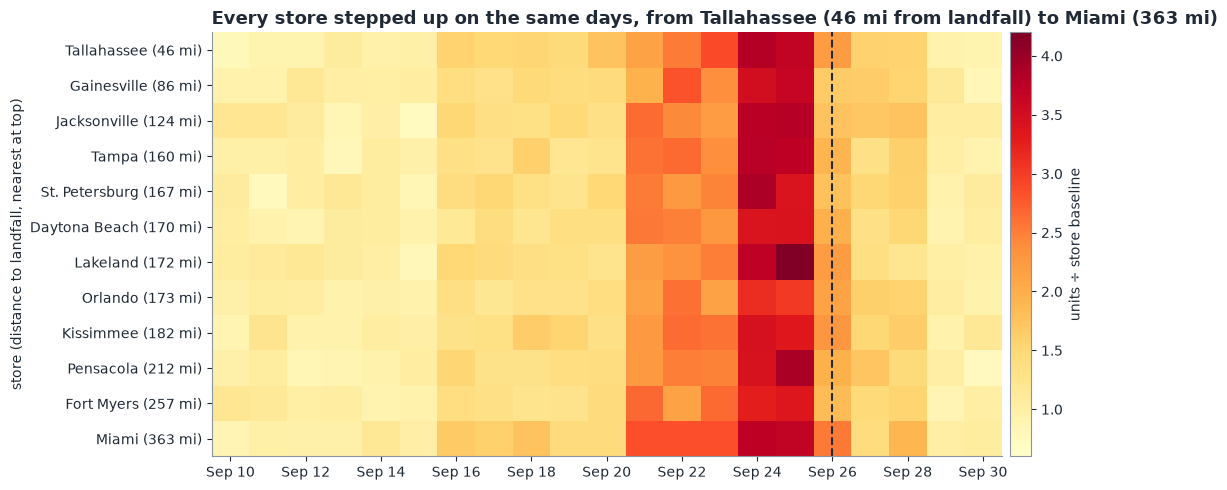

In [35]:
fig, ax = plt.subplots(figsize=(11, 5))
show = store_index.loc['2024-09-10':'2024-09-30'].T
labels = [f"{c} ({int(d)} mi)" for c, d in zip(stores['city'], stores['dist_to_landfall_mi'])]
im = ax.imshow(show.values, aspect='auto', cmap='YlOrRd', vmin=0.6, vmax=4.2)
ax.set_yticks(range(len(labels)), labels)
ax.set_xticks(range(0, show.shape[1], 2), [d.strftime('%b %d') for d in show.columns[::2]], rotation=0)
ax.axvline(list(show.columns).index(LANDFALL_DAY), color=INK, lw=1.5, ls='--')
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01, label='units ÷ store baseline')
ax.set_title('Every store stepped up on the same days, from Tallahassee (46 mi from landfall) to Miami (363 mi)')
ax.set_ylabel('store (distance to landfall, nearest at top)')
plt.tight_layout(); save(fig, '07_q4_store_heatmap'); plt.show()

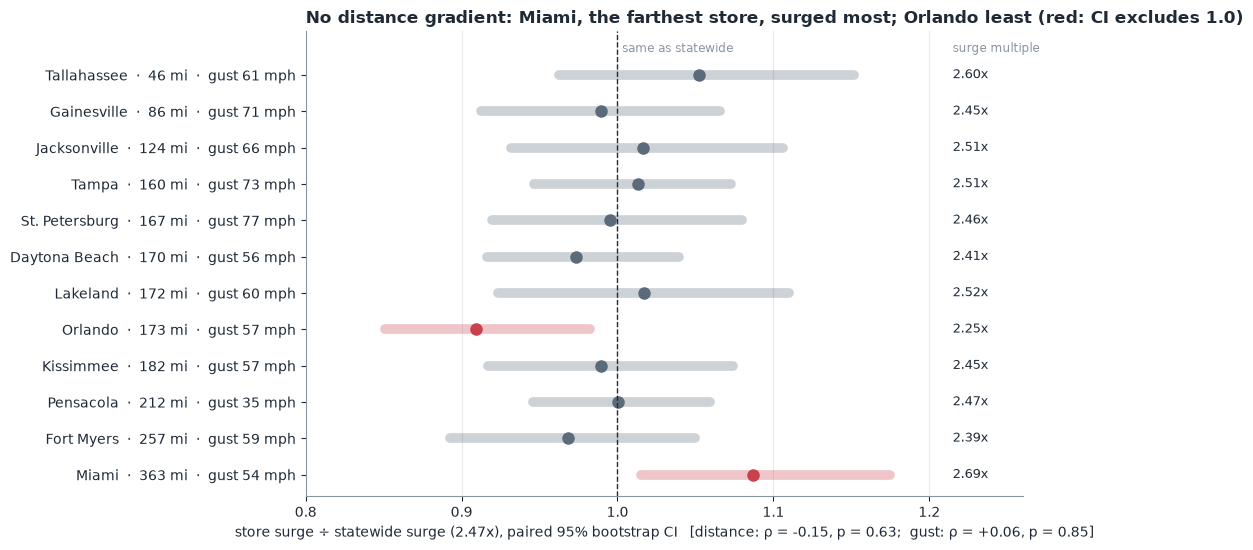

In [36]:
plot = q4.sort_values('dist_to_landfall_mi', ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10.5, 5.6))
for y, r in plot.iterrows():
    color = RED if r['outlier'] else SLATE
    ax.plot([r['ci_low'], r['ci_high']], [y, y], color=color, alpha=0.3, lw=7, solid_capstyle='round')
    ax.plot(r['vs_statewide'], y, 'o', color=color, ms=8)
    ax.text(1.215, y, f"{r['surge_multiple']:.2f}x", va='center', fontsize=9, color=INK)
ax.set_yticks(range(len(plot)),
              [f"{c}  ·  {int(d)} mi  ·  gust {g:.0f} mph" for c, d, g in
               zip(plot['city'], plot['dist_to_landfall_mi'], plot['max_gust_sep25_27_mph'])])
ax.axvline(1, color=INK, lw=1, ls='--')
ax.set_xlim(0.8, 1.26)
ax.set_ylim(-0.6, len(plot) + 0.2)
ax.text(1.215, len(plot) - 0.45, 'surge multiple', fontsize=8.5, color=MUTED, va='bottom')
ax.text(1.003, len(plot) - 0.45, 'same as statewide', fontsize=8.5, color=MUTED, va='bottom')
ax.set_xlabel(f'store surge ÷ statewide surge ({statewide_multiple:.2f}x), paired 95% bootstrap CI   '
              f'[distance: ρ = {rho_dist:+.2f}, p = {p_dist:.2f};  gust: ρ = {rho_gust:+.2f}, p = {p_gust:.2f}]')
ax.grid(axis='y', visible=False)
ax.set_title('No distance gradient: Miami, the farthest store, surged most; Orlando least (red: CI excludes 1.0)', fontsize=12)
plt.tight_layout(); save(fig, '08_q4_store_vs_statewide'); plt.show()

In [37]:
# What makes the outliers different? Compare their category mix with the other stores
out_ids = q4.loc[q4['outlier'], 'store_id'].tolist()
store_cat = (tx[tx['date'].between(*SURGE)].pivot_table(index='store_id', columns='category', values='quantity', aggfunc='sum') / 7) / \
            (tx[tx['date'].between(*BASELINE)].pivot_table(index='store_id', columns='category', values='quantity', aggfunc='sum') / 15)
compare = pd.DataFrame({q4.set_index('store_id').loc[sid, 'city']: store_cat.loc[sid] for sid in out_ids})
compare['median of other stores'] = store_cat.drop(index=out_ids).median()
print('Outlier stores:', q4.loc[q4['outlier'], ['city', 'surge_multiple', 'vs_statewide', 'ci_low', 'ci_high', 'robust_z']]
      .round(2).to_dict('records'))
compare.round(2).sort_values('median of other stores', ascending=False)

Outlier stores: [{'city': 'Orlando', 'surge_multiple': 2.25, 'vs_statewide': 0.91, 'ci_low': 0.85, 'ci_high': 0.98, 'robust_z': -3.17}, {'city': 'Miami', 'surge_multiple': 2.69, 'vs_statewide': 1.09, 'ci_low': 1.02, 'ci_high': 1.17, 'robust_z': 3.16}]


,Orlando,Miami,median of other stores
category,,,
Breakfast,4.49,6.98,5.49
Emergency,2.63,2.97,2.87
Electronics,2.51,2.70,2.43
Alcohol,1.68,2.39,2.38
Entertainment,2.45,2.19,2.32
Household,1.82,1.96,2.18
Health,1.93,3.10,2.16
Grocery,1.76,1.94,1.80
Baby,1.49,1.78,1.49


**Answer (Q4).** No. Eleven of 12 stores stepped up on Sept 16 and every store peaked on Sept 24 or 25. Surge size isn't related to distance (ρ = −0.15, p = 0.63) or local gusts (ρ = +0.06, p = 0.85).

Two stores stand out, against a distance story: Miami, the farthest store, surged 9% more than the state, mostly in Breakfast and Health, and Orlando surged 9% less. With 12 stores tested, one false positive is expected by chance, so these are worth watching rather than acting on. Surge stock should go to every store in proportion to its normal volume.

---
## Q5. Board games: a real demand signal or a data artifact?

The case reports board games up 250%. We test whether that comes from the query, a reporting lag, category lumping, SKU miscoding, or simply more shoppers, and check what the inventory feed shows.

In [38]:
# 5.1 Reproduce the headline from SQLite: naive text-date query vs. fixed query
con = sqlite3.connect(DATA / 'inventory_and_sales.db')
NAIVE_SQL = '''
SELECT date, SUM(total_units) AS units, COUNT(*) AS rows_read
FROM daily_sales_summary
WHERE category = 'Entertainment' AND date BETWEEN '2024-09-01' AND '2024-09-30'
GROUP BY date'''
naive_ent = pd.read_sql(NAIVE_SQL, con, parse_dates=['date']).set_index('date')
fixed_ent = pd.read_sql(f"SELECT * FROM ({DSS_SQL}) WHERE category = 'Entertainment'", con, parse_dates=['date'])
con.close()
fixed_ent_daily = fixed_ent.groupby('date')['total_units'].sum().reindex(SEPT)


def headline(daily, label, rows):
    b = daily.loc[BASELINE[0]:BASELINE[1]].mean()
    return {'query': label, 'rows_read': rows, 'baseline/day': b,
            'surge/day': daily.loc[SURGE[0]:SURGE[1]].mean(), 'peak/day': daily.loc[PEAK[0]:PEAK[1]].mean(),
            'surge_%': 100 * (daily.loc[SURGE[0]:SURGE[1]].mean() / b - 1),
            'peak_%': 100 * (daily.loc[PEAK[0]:PEAK[1]].mean() / b - 1)}


# Naive daily totals silently miss the YYYYMMDD rows, so some store-days are simply absent from those days
headline_tbl = pd.DataFrame([
    headline(naive_ent['units'].reindex(SEPT), 'naive: WHERE date BETWEEN (text)', int(naive_ent['rows_read'].sum())),
    headline(fixed_ent_daily, 'fixed: dates normalized in SQL', len(fixed_ent)),
]).set_index('query')
display(headline_tbl.round(1))
print(f'Entertainment rows in the table: {len(fixed_ent)}; the naive query read {int(naive_ent["rows_read"].sum())} '
      f'and silently skipped {len(fixed_ent) - int(naive_ent["rows_read"].sum())}.')

,rows_read,baseline/day,surge/day,peak/day,surge_%,peak_%
query,,,,,,
naive: WHERE date BETWEEN (text),338,537.4,1333.4,2030.0,148.1,277.7
fixed: dates normalized in SQL,360,568.5,1394.5,2083.5,145.3,266.5


Entertainment rows in the table: 360; the naive query read 338 and silently skipped 22.


In [39]:
# 5.2 Does the database agree with the registers, and is either one lagged?
pos_ent = cat_daily['Entertainment']
ratio = fixed_ent_daily / pos_ent
xcorr = pd.Series({k: fixed_ent_daily.corr(pos_ent.shift(k)) for k in range(-3, 4)}, name='r')
print(f'Same-day correlation, database vs POS Entertainment units: r = {fixed_ent_daily.corr(pos_ent):.2f} (n = 30)')
print('Cross-correlation by lag (POS shifted k days):', xcorr.round(2).to_dict())
print(f'Database ÷ POS units, baseline: {ratio.loc[BASELINE[0]:BASELINE[1]].mean():.2f}  |  '
      f'surge window: {ratio.loc[SURGE[0]:SURGE[1]].mean():.2f}  '
      '(the database covers more volume than the POS extract, but the ratio does not jump in the surge)')

Same-day correlation, database vs POS Entertainment units: r = 0.96 (n = 30)
Cross-correlation by lag (POS shifted k days): {-3: 0.49, -2: 0.6, -1: 0.84, 0: 0.96, 1: 0.7, 2: 0.43, 3: 0.29}
Database ÷ POS units, baseline: 5.42  |  surge window: 5.76  (the database covers more volume than the POS extract, but the ratio does not jump in the surge)


In [40]:
# 5.3 Split the category, and 5.4 audit the board-game SKUs
ENT_PRODUCTS = ['Monopoly Board Game', 'Playing Cards']
ent = tx[tx['category'] == 'Entertainment']
print('Products inside Entertainment:', sorted(ent['product'].unique()), '| SKUs:', sorted(ent['sku'].unique()))
print('Streaming sticks are coded Electronics in both the POS data and the catalog:',
      sorted(tx.loc[tx['product'] == 'Streaming Stick', 'category'].unique()))

split = surge_table(prod_daily[ENT_PRODUCTS].assign(**{'Entertainment (lumped)': cat_daily['Entertainment']}))
display(split[['baseline_per_day', 'surge_per_day', 'peak_per_day', 'surge_pct_increase', 'peak_pct_increase']].round(1))

tx['window'] = np.select([tx['date'].between(*BASELINE), tx['date'].between(*SURGE)], ['baseline', 'surge'], 'other')
bg = tx[(tx['product'] == 'Monopoly Board Game') & (tx['window'] != 'other')]
audit = bg.pivot_table(index='sku', columns='window', values=['unit_price', 'quantity'], aggfunc='mean').round(2)
sku_units = bg.pivot_table(index='sku', columns='window', values='quantity', aggfunc='sum')
audit[('surge multiple', '')] = ((sku_units['surge'] / 7) / (sku_units['baseline'] / 15)).round(2)
audit.columns = [' '.join(c).strip() for c in audit.columns]
audit = audit.rename(columns={'quantity baseline': 'units/line baseline', 'quantity surge': 'units/line surge',
                              'unit_price baseline': 'price baseline', 'unit_price surge': 'price surge'})
print('Board-game SKU audit (card prices would be about $5.00; Monopoly sells at about $20):')
display(audit)
stores_up = (tx[tx['product'] == 'Monopoly Board Game'].pivot_table(index='date', columns='store_id', values='quantity', aggfunc='sum')
             .reindex(SEPT).fillna(0))
bg_store_mult = stores_up.loc[SURGE[0]:SURGE[1]].mean() / stores_up.loc[BASELINE[0]:BASELINE[1]].mean()
print(f'Board-game surge multiple by store: min {bg_store_mult.min():.2f}x, max {bg_store_mult.max():.2f}x; '
      f'{(bg_store_mult > 1.5).sum()} of 12 stores above 1.5x')

Products inside Entertainment: ['Monopoly Board Game', 'Playing Cards'] | SKUs: ['BG-MONO', 'CARDS-01', 'GAME-MONO', 'MONOPOLY-01', 'PLAYCARD-STD']
Streaming sticks are coded Electronics in both the POS data and the catalog: ['Electronics']


,baseline_per_day,surge_per_day,peak_per_day,surge_pct_increase,peak_pct_increase
product,,,,,
Monopoly Board Game,44.5,118.9,186.5,167.3,319.4
Playing Cards,60.9,122.0,166.5,100.2,173.2
Entertainment (lumped),105.4,240.9,353.0,128.5,234.9


Board-game SKU audit (card prices would be about $5.00; Monopoly sells at about $20):


,units/line baseline,units/line surge,price baseline,price surge,surge multiple
sku,,,,,
BG-MONO,1.53,1.53,20.02,20.00,2.75
GAME-MONO,1.55,1.48,20.03,20.00,2.39
MONOPOLY-01,1.47,1.50,20.02,20.04,2.93


Board-game surge multiple by store: min 2.01x, max 3.59x; 12 of 12 stores above 1.5x


Correlation of daily mean on-hand between families (all ≈ 1 means the feed moves in lockstep):


family,Board games,Orphan codes (no product),Other catalog SKUs,Playing cards,Pop-Tarts,Water
family,,,,,,
Board games,1.00,0.83,0.95,0.89,0.87,0.90
Orphan codes (no product),0.83,1.00,0.92,0.91,0.93,0.84
Other catalog SKUs,0.95,0.92,1.00,0.95,0.95,0.94
Playing cards,0.89,0.91,0.95,1.00,0.89,0.88
Pop-Tarts,0.87,0.93,0.95,0.89,1.00,0.89
Water,0.90,0.84,0.94,0.88,0.89,1.00


Change in mean on-hand from Sept 11 to Sept 12, every family: {'Board games': 2.32, 'Orphan codes (no product)': 3.4, 'Other catalog SKUs': 2.13, 'Playing cards': 2.96, 'Pop-Tarts': 1.96, 'Water': 1.7}


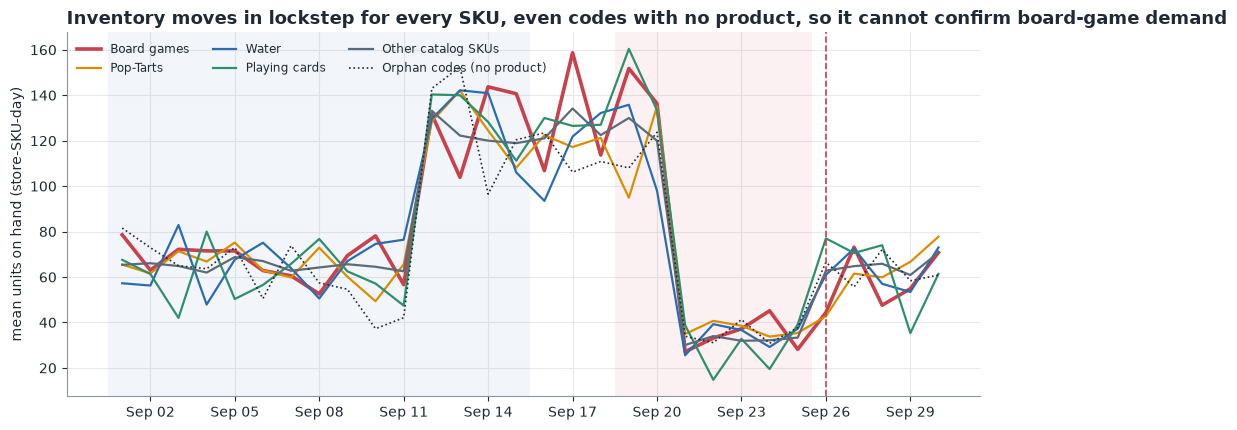

In [41]:
# 5.5 Does the inventory feed show board games selling through faster than other products?
family = {'BOARDGAME-MONOPOLY': 'Board games', 'PLAYING-CARDS': 'Playing cards',
          'POPTARTS-STRAWBERRY': 'Pop-Tarts', 'WATER-24PK': 'Water'}
inv['family'] = inv['product_id'].map(family).fillna(
    pd.Series(np.where(inv['in_catalog'], 'Other catalog SKUs', 'Orphan codes (no product)'), index=inv.index))
onhand = inv.groupby(['date', 'family'])['units_on_hand'].mean().unstack().reindex(SEPT)
print('Correlation of daily mean on-hand between families (all ≈ 1 means the feed moves in lockstep):')
display(onhand.corr().round(2))
jump = onhand.loc['2024-09-12'] / onhand.loc['2024-09-11']
print('Change in mean on-hand from Sept 11 to Sept 12, every family:', jump.round(2).to_dict())

fig, ax = plt.subplots(figsize=(10, 4.4))
styles = {'Board games': (RED, 2.6), 'Pop-Tarts': (GOLD, 1.6), 'Water': (BLUE, 1.6), 'Playing cards': (GREEN, 1.6),
          'Other catalog SKUs': (SLATE, 1.6), 'Orphan codes (no product)': (INK, 1.2)}
for fam_name, (color, lw) in styles.items():
    ax.plot(SEPT, onhand[fam_name], color=color, lw=lw, label=fam_name,
            ls=':' if fam_name.startswith('Orphan') else '-')
mark_windows(ax, label=False)
date_axis(ax)
ax.set_ylabel('mean units on hand (store-SKU-day)')
ax.set_title('Inventory moves in lockstep for every SKU, even codes with no product, so it cannot confirm board-game demand')
ax.legend(ncols=3, fontsize=8.5, loc='upper left')
plt.tight_layout(); save(fig, '09_q5_inventory_lockstep'); plt.show()

Store traffic (all units) multiple in the surge window: 2.47x


,lift_vs_traffic,ci_low,ci_high,share_baseline_%,share_surge_%
product,,,,,
Pop-Tarts Strawberry,2.12,1.83,2.38,6.57,13.92
Bottled Water 24-Pack,1.21,1.09,1.35,9.74,11.83
Heavy Duty Tarp,1.21,1.09,1.31,3.93,4.75
LED Flashlight,1.20,1.03,1.36,5.19,6.23
AA Batteries 4-Pack,1.11,1.03,1.20,8.02,8.92
Monopoly Board Game,1.08,0.96,1.19,3.89,4.21
Portable Phone Charger,1.04,0.94,1.16,3.92,4.09
Emergency Candles,1.04,0.94,1.16,5.13,5.33
Streaming Stick,0.92,0.87,0.97,2.53,2.33


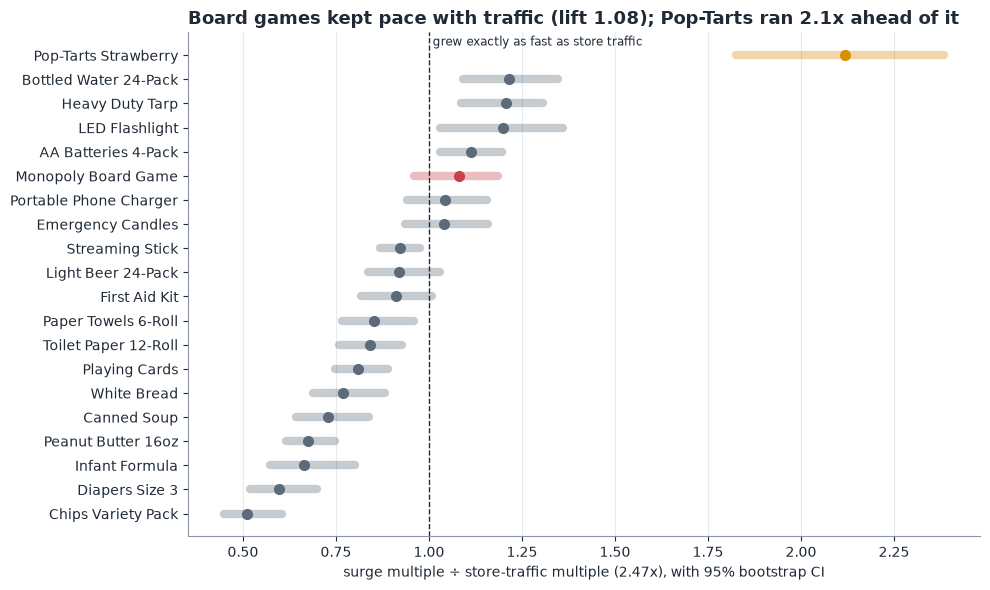

In [42]:
# 5.6 Lift beyond store traffic: product multiple ÷ all-units multiple, with a day-level bootstrap CI
total_daily = cat_daily['ALL CATEGORIES']
b_idx = np.where((SEPT >= BASELINE[0]) & (SEPT <= BASELINE[1]))[0]
s_idx = np.where((SEPT >= SURGE[0]) & (SEPT <= SURGE[1]))[0]
B = 5000
bi = rng.integers(0, len(b_idx), size=(B, len(b_idx)))
si = rng.integers(0, len(s_idx), size=(B, len(s_idx)))


def lift_ci(series):
    # Resample the same days for the product and for total traffic, so the ratio is paired
    p, t = series.values, total_daily.values
    prod_mult = p[s_idx][si].mean(1) / p[b_idx][bi].mean(1)
    traf_mult = t[s_idx][si].mean(1) / t[b_idx][bi].mean(1)
    lift = prod_mult / traf_mult
    point = (p[s_idx].mean() / p[b_idx].mean()) / (t[s_idx].mean() / t[b_idx].mean())
    return point, np.percentile(lift, 2.5), np.percentile(lift, 97.5)


lift = pd.DataFrame([(prod, *lift_ci(prod_daily[prod])) for prod in prod_daily.columns],
                    columns=['product', 'lift_vs_traffic', 'ci_low', 'ci_high']).set_index('product')
lift['share_baseline_%'] = 100 * prod_daily.loc[BASELINE[0]:BASELINE[1]].sum() / total_daily.loc[BASELINE[0]:BASELINE[1]].sum()
lift['share_surge_%'] = 100 * prod_daily.loc[SURGE[0]:SURGE[1]].sum() / total_daily.loc[SURGE[0]:SURGE[1]].sum()
lift = lift.sort_values('lift_vs_traffic')
traffic_multiple = total_daily.loc[SURGE[0]:SURGE[1]].mean() / total_daily.loc[BASELINE[0]:BASELINE[1]].mean()
print(f'Store traffic (all units) multiple in the surge window: {traffic_multiple:.2f}x')
display(lift.round(2).iloc[::-1])

fig, ax = plt.subplots(figsize=(10, 6))
for y, (prod, r) in enumerate(lift.iterrows()):
    color = RED if prod == 'Monopoly Board Game' else (GOLD if prod == 'Pop-Tarts Strawberry' else SLATE)
    ax.plot([r['ci_low'], r['ci_high']], [y, y], color=color, alpha=0.35, lw=6, solid_capstyle='round')
    ax.plot(r['lift_vs_traffic'], y, 'o', color=color, ms=7)
ax.set_yticks(range(len(lift)), lift.index)
ax.axvline(1, color=INK, lw=1, ls='--')
ax.text(1.01, len(lift) - 0.6, 'grew exactly as fast as store traffic', fontsize=8.5)
ax.set_xlabel(f'surge multiple ÷ store-traffic multiple ({traffic_multiple:.2f}x), with 95% bootstrap CI')
bgl = lift.loc['Monopoly Board Game']
ax.set_title(f'Board games kept pace with traffic (lift {bgl["lift_vs_traffic"]:.2f}); Pop-Tarts ran '
             f'{lift.loc["Pop-Tarts Strawberry", "lift_vs_traffic"]:.1f}x ahead of it')
ax.grid(axis='y', visible=False)
plt.tight_layout(); save(fig, '10_q5_lift_vs_traffic'); plt.show()

**Answer (Q5).** The rise is real sales, but it isn't a storm signal.

The database reproduces the jump (+267% on the peak days) once its text dates are fixed, and it matches the registers with no lag. "Entertainment" lumps Monopoly with playing cards, but board games are the stronger of the two. There is no sign of miscoding: all three Monopoly SKUs rose, in every store, at a steady $20. The inventory feed moves identically for every SKU, so it can't confirm anything either way.

The deciding test is traffic. Store traffic rose 2.47× and board games 2.67×, a lift of 1.08 (95% CI 0.96–1.19), so they grew with the number of shoppers. Pop-Tarts' lift was 2.1.

Walmart should keep board games stocked in line with traffic (about 2.5× normal before a storm) but not give them surge truck capacity. Checking the same lift across other storms would settle it.

---
## Recommendation to Walmart leadership

Trigger restocking on the NHC forecast about 10 days out, when demand first rose, and build stock in steps: about 1.4× normal at T−10, 2.5× at T−5 and 3.6× at T−2.

Ship early. Peak demand was 3.6× normal, but all five distribution centers together can only surge to about 2×, so stock has to reach stores before the peak. Jacksonville is the closest and cheapest DC, with Miami covering the south.

Give truck priority to products that grow faster than traffic: Pop-Tarts first, then water, tarps, flashlights and batteries. Everything else, including board games, should scale with traffic. Allocate to every store in proportion to its normal volume, since distance to the storm didn't predict the surge.

Before the next storm, fix the pipeline issues found here: maintain the SKU map, store real dates in SQLite, and convert weather time zones in-house.

In [43]:
# Supply-side check behind the recommendation: can the DC network absorb the peak?
network = dcs[['dc_id', 'city', 'avg_daily_shipments', 'surge_capacity', 'surge_capacity_approx', 'cost_per_shipment']].copy()
network['surge_headroom_x'] = network['surge_capacity'] / network['avg_daily_shipments']
total_headroom = network['surge_capacity'].sum() / network['avg_daily_shipments'].sum()
demand = pd.Series({'surge window (Sept 19-25)': traffic_multiple,
                    'peak days (Sept 24-25)': total_daily.loc[PEAK[0]:PEAK[1]].mean() / total_daily.loc[BASELINE[0]:BASELINE[1]].mean(),
                    'Pop-Tarts, peak days': prod_daily.loc[PEAK[0]:PEAK[1], 'Pop-Tarts Strawberry'].mean()
                                            / prod_daily.loc[BASELINE[0]:BASELINE[1], 'Pop-Tarts Strawberry'].mean()})
display(network.round(2))
print(f'All five DCs at surge capacity: {total_headroom:.2f}x normal shipments')
print('Demand multiples to cover:', demand.round(2).to_dict())

,dc_id,city,avg_daily_shipments,surge_capacity,surge_capacity_approx,cost_per_shipment,surge_headroom_x
0,DC-JAX,Jacksonville,500,1000,False,245.0,2.00
1,DC-ATL,Atlanta,400,700,False,412.5,1.75
2,DC-DAL,Dallas,300,600,False,687.0,2.00
3,DC-MIA,Miami,350,750,True,298.0,2.14
4,DC-BHM,Birmingham,250,500,False,NaN,2.00


All five DCs at surge capacity: 1.97x normal shipments
Demand multiples to cover: {'surge window (Sept 19-25)': 2.47, 'peak days (Sept 24-25)': 3.58, 'Pop-Tarts, peak days': 8.7}


---
## Limitations

All results come from one storm, one month and 12 stores, and the course data is synthetic. Observed weather can't stand in for the forecast that drives buying. We assumed every register logs Eastern time, including Pensacola, which is on Central time. The correlations describe Helene; they don't establish cause.

---
## Reflection

The five reflection answers are in **`REFLECTION.md`**